In [2]:
DATASET_PATH = "./data/02_octopus/static_analysis/"
import os
import pandas as pd
import json


In [3]:
%pip install seaborn matplotlib jinja2

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: /Applications/Xcode.app/Contents/Developer/usr/bin/python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
# ==============================================================================
# 1. SPLIT THE MASTER SCANNER REPORT BY CLASS
# ==============================================================================
print("Splitting apk_scanner_report.jsonl by scanner class...")
output_files = {}
input_filepath = f"{DATASET_PATH}apk_scanner_report.jsonl"

try:
    with open(input_filepath, 'r') as infile:
        for line in infile:
            try:
                record = json.loads(line)
                cls_name = record.get('_cls', 'Unknown_Cls')

                if cls_name not in output_files:
                    safe_filename = f"{DATASET_PATH}{cls_name.replace('.', '_')}.jsonl"
                    output_files[cls_name] = open(safe_filename, 'w')

                output_files[cls_name].write(line)
            except json.JSONDecodeError:
                continue
finally:
    for f in output_files.values():
        f.close()

generated_classes = list(output_files.keys())
print(f"File splitting complete. Created {len(generated_classes)} files: {generated_classes}\n")


# ==============================================================================
# 2. BUILD THE UNIVERSAL FIRMWARE MAPPING TABLE (WITH FIRMWARE_ID ENRICHMENT)
# ==============================================================================
print("Loading android_firmware.jsonl to build firmware mapping...")

def extract_oid(val):
    """Safely extracts string ID from MongoDB {'$oid': '...'} dicts."""
    if isinstance(val, dict) and '$oid' in val:
        return val['$oid']
    return str(val)

# Load firmware data
df_firmware = pd.read_json(f"{DATASET_PATH}android_firmware.jsonl", lines=True)

if '_id' in df_firmware.columns:
    df_firmware['firmware_id'] = df_firmware['_id'].apply(extract_oid)

# Drop heavy file lists immediately to conserve RAM
cols_to_drop = ['firmware_file_id_list', 'build_prop_file_id_list', '_id']
df_firmware = df_firmware.drop(columns=[col for col in cols_to_drop if col in df_firmware.columns])

target_cols = ['android_app_id_list', 'os_vendor', 'version_detected', 'firmware_id']
available_cols = [col for col in target_cols if col in df_firmware.columns]

df_fw_subset = df_firmware[available_cols].copy()
df_fw_mapping = df_fw_subset.explode('android_app_id_list').dropna(subset=['android_app_id_list'])

# Clean firmware app references to ensure perfect matching
df_fw_mapping['android_app_id_reference'] = df_fw_mapping['android_app_id_list'].apply(extract_oid)
df_fw_mapping = df_fw_mapping.drop(columns=['android_app_id_list'])

df_fw_mapping = df_fw_mapping.drop_duplicates(subset=['android_app_id_reference'])
print(f"Created firmware lookup table with {len(df_fw_mapping)} unique apps.\n")


# ==============================================================================
# 3. BUILD THE APP METADATA MAPPING TABLE
# ==============================================================================
print("Loading android_app.jsonl to build app metadata mapping...")

# Load app metadata
df_app = pd.read_json(f"{DATASET_PATH}android_app.jsonl", lines=True)

# Standardize the ID field to match our join key
if '_id' in df_app.columns:
    df_app['android_app_id_reference'] = df_app['_id'].apply(extract_oid)

# Filter down to just the join key and the requested fields to save memory
app_target_cols = ['android_app_id_reference', 'filename', 'partition_name', 'absolute_store_path']
app_available_cols = [col for col in app_target_cols if col in df_app.columns]

df_app_mapping = df_app[app_available_cols].copy()

# Ensure uniqueness on the join key
df_app_mapping = df_app_mapping.drop_duplicates(subset=['android_app_id_reference'])
print(f"Created app metadata lookup table with {len(df_app_mapping)} unique apps.\n")


# ==============================================================================
# 4. PROCESS AND ENRICH ALL SCANNER REPORTS
# ==============================================================================
enriched_reports = {}

for cls_name in generated_classes:
    safe_cls_name = cls_name.replace('.', '_')
    file_path = f"{DATASET_PATH}{safe_cls_name}.jsonl"

    print(f"Processing: {safe_cls_name}...")

    # 1. Load the scanner-specific JSONL
    df_scanner = pd.read_json(file_path, lines=True)
    df_scanner = df_scanner.reset_index(drop=True)

    # 2. Flatten the nested 'results' dictionary if it exists
    if 'results' in df_scanner.columns:
        df_scanner['results'] = df_scanner['results'].apply(lambda x: x if isinstance(x, dict) else {})
        df_results_flat = pd.json_normalize(df_scanner['results'])
        df_scanner = pd.concat([df_scanner.drop(columns=['results']), df_results_flat], axis=1)

    # Clean the scanner database _id for safety
    if '_id' in df_scanner.columns:
        df_scanner['_id'] = df_scanner['_id'].apply(extract_oid)

    # 3. Clean the App ID reference for merging
    if 'android_app_id_reference' in df_scanner.columns:
        df_scanner['android_app_id_reference'] = df_scanner['android_app_id_reference'].apply(extract_oid)

        # 4a. Enrich with firmware data
        df_enriched = pd.merge(
            df_scanner,
            df_fw_mapping,
            on='android_app_id_reference',
            how='left'
        )

        # 4b. Enrich with app metadata
        df_enriched = pd.merge(
            df_enriched,
            df_app_mapping,
            on='android_app_id_reference',
            how='left'
        )
    else:
        print(f"  -> WARNING: 'android_app_id_reference' missing in {safe_cls_name}. Skipping enrichment.")
        df_enriched = df_scanner

    # Store in our dictionary
    enriched_reports[safe_cls_name] = df_enriched
    print(f"  -> Success! Final shape: {df_enriched.shape}")

print("\nAll reports successfully flattened and enriched.")

Splitting apk_scanner_report.jsonl by scanner class...
File splitting complete. Created 2 files: ['ApkScannerReport.ExodusReport', 'ApkScannerReport.AndroGuardReport']

Loading android_firmware.jsonl to build firmware mapping...
Created firmware lookup table with 864150 unique apps.

Loading android_app.jsonl to build app metadata mapping...
Created app metadata lookup table with 864203 unique apps.

Processing: ApkScannerReport_ExodusReport...
  -> Success! Final shape: (339243, 23)
Processing: ApkScannerReport_AndroGuardReport...
  -> Success! Final shape: (3971, 49)

All reports successfully flattened and enriched.


In [5]:
# ==========================================
# 6. FILTER BY SPECIFIC ANDROID VERSIONS & SCAN STATUS
# ==========================================
df_exodus = enriched_reports["ApkScannerReport_ExodusReport"]

version_col = 'version_detected'
status_col = 'scan_status'

# 1. CRITICAL FIX: Filter out all failed scan results
# We check if the column exists first to protect against KeyError anomalies
if status_col in df_exodus.columns:
    initial_shape = df_exodus.shape[0]
    df_exodus = df_exodus[df_exodus[status_col] != "failed"]
    dropped_scans = initial_shape - df_exodus.shape[0]
    print(f"Dropped {dropped_scans} failed scans from the dataset.")

# 2. Drop rows where the version is completely missing
df_exodus = df_exodus.dropna(subset=[version_col])

# 3. Clean up the version values: convert to numeric, turning anomalies into NaN safely
df_exodus[version_col] = pd.to_numeric(df_exodus[version_col], errors='coerce')

# 4. Filter strictly for target versions (12, 13, 14, 15)
# Note: Adjusted print statement to match target_versions array bounds exactly
target_versions = [12, 13, 14, 15]
df_exodus = df_exodus[df_exodus[version_col].dropna().astype(int).isin(target_versions)].copy()

# 5. Force column type to integer so it prints cleanly in future plots and tables
df_exodus[version_col] = df_exodus[version_col].astype(int)

print(f"Filtered Dataset Shape: {df_exodus.shape} (Removed versions outside of 12-15)")
print(f"Remaining unique versions in data: {sorted(df_exodus[version_col].unique())}")

Dropped 10029 failed scans from the dataset.
Filtered Dataset Shape: (313946, 23) (Removed versions outside of 12-15)
Remaining unique versions in data: [12, 13, 14, 15]


In [6]:
df_exodus.head()

,_id,_cls,report_date,android_app_id_reference,scanner_version,scanner_name,scan_status,error,trackers,application.handle,...,application.name,application.permissions,application.libraries,apk.path,apk.checksum,os_vendor,version_detected,firmware_id,filename,partition_name
960,6a4f4eb122324e493b7a8e3d,ApkScannerReport.ExodusReport,2026-07-09T07:33:02.498000,68b105d665e2ad36cf065848,1.3.12,Exodus,completed,NaN,[],com.android.bookmarkprovider,...,Bookmark Provider,[],[],/var/www/file_store/01_file_storage/dc63ac8b-3...,b5d8898df49761cf62820f07d8f784b7ad26a147ad1e8a...,Google,12,68b1075d65e2ad36cf0776d5,BookmarkProvider.apk,system
961,6a4f4eb1fa7e8ee5127a8e3d,ApkScannerReport.ExodusReport,2026-07-09T07:33:01.800000,68b105d665e2ad36cf065844,1.3.12,Exodus,completed,NaN,[],com.android.bluetoothmidiservice,...,Bluetooth MIDI Service,"[android.permission.BLUETOOTH_SCAN, android.pe...",[],/var/www/file_store/01_file_storage/dc63ac8b-3...,911cdf6c13fd0b3d3c432c661ee1dab4edbd8cc1bed0cc...,Google,12,68b1075d65e2ad36cf0776d5,BluetoothMidiService.apk,system
962,6a4f4eb256df774d197a8e3d,ApkScannerReport.ExodusReport,2026-07-09T07:33:03.001000,68b105d665e2ad36cf06582e,1.3.12,Exodus,completed,NaN,[],com.android.dreams.basic,...,Basic Daydreams,[],[],/var/www/file_store/01_file_storage/dc63ac8b-3...,5a0900ec7b89f0ac562506e6ddc6b62c3ec52a532bec40...,Google,12,68b1075d65e2ad36cf0776d5,BasicDreams.apk,system
963,6a4f4eb28147f5ecd97a8e3d,ApkScannerReport.ExodusReport,2026-07-09T07:33:02.704000,68b105d765e2ad36cf065944,1.3.12,Exodus,completed,NaN,[],com.android.providers.partnerbookmarks,...,,[],[],/var/www/file_store/01_file_storage/dc63ac8b-3...,67d14c800a89b54e33ffa1979a23f7c47dd1a6db18b42f...,Google,12,68b1075d65e2ad36cf0776d5,PartnerBookmarksProvider.apk,system
964,6a4f4eb31aea578a3f7a8e3d,ApkScannerReport.ExodusReport,2026-07-09T07:33:05.799000,68b105d765e2ad36cf065892,1.3.12,Exodus,completed,NaN,[],com.android.htmlviewer,...,HTML Viewer,[],[],/var/www/file_store/01_file_storage/dc63ac8b-3...,3c2dddb9262839eab44ac89b6f20678734a7126aa6fb1b...,Google,12,68b1075d65e2ad36cf0776d5,HTMLViewer.apk,system


In [7]:
df_exodus_enriched = df_exodus
df_exodus_final = df_exodus

print(f"Loaded {len(df_exodus)} rows.")
print(df_exodus.columns)

Loaded 313946 rows.
Index(['_id', '_cls', 'report_date', 'android_app_id_reference',
       'scanner_version', 'scanner_name', 'scan_status', 'error', 'trackers',
       'application.handle', 'application.version_name',
       'application.version_code', 'application.uaid', 'application.name',
       'application.permissions', 'application.libraries', 'apk.path',
       'apk.checksum', 'os_vendor', 'version_detected', 'firmware_id',
       'filename', 'partition_name'],
      dtype='object')


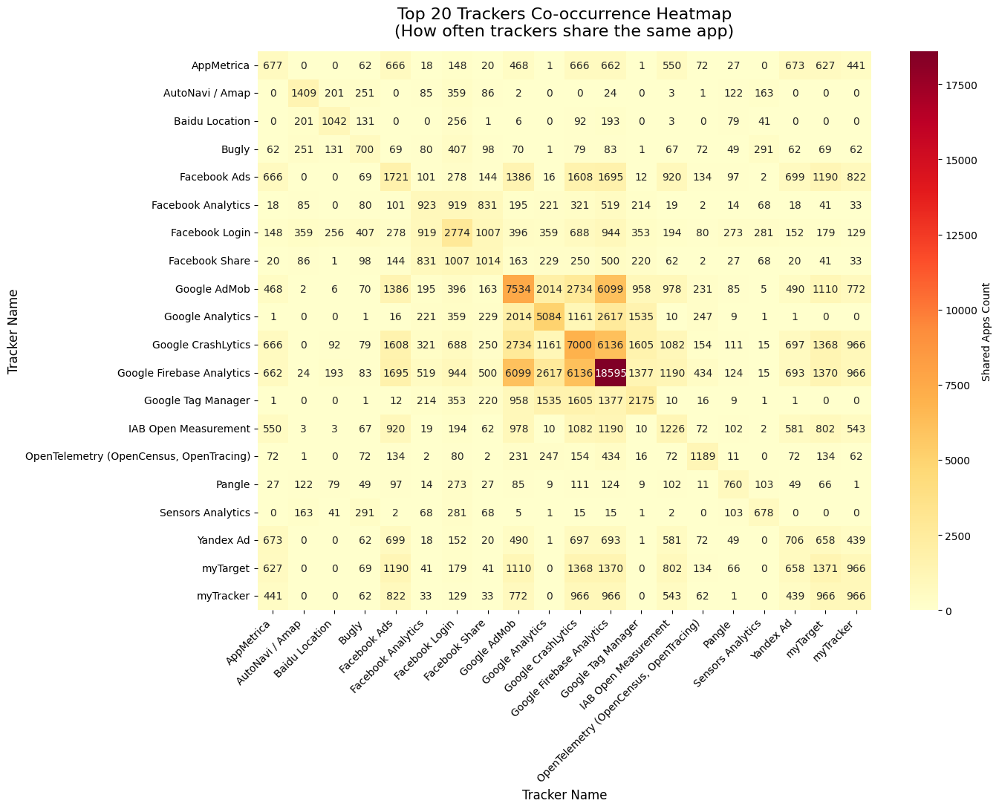

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ==========================================
# STEP 1: SAFE EXTRACTION & PREPARATION
# ==========================================

def extract_tracker_names(tracker_list):
    if not isinstance(tracker_list, list):
        return []
    names = []
    for t in tracker_list:
        if isinstance(t, dict) and 'name' in t:
            names.append(t['name'])
        elif isinstance(t, str):
            names.append(t)
    return names

# Clean up tracker columns and explode the list
df_exodus_final['tracker_names'] = df_exodus_final['trackers'].apply(extract_tracker_names)
df_trackers_exploded = df_exodus_final.explode('tracker_names').dropna(subset=['tracker_names'])

# Fill missing application handles with a placeholder for the visualization
if 'application.handle' in df_trackers_exploded.columns:
    df_trackers_exploded['application.handle'] = df_trackers_exploded['application.handle'].fillna(df_trackers_exploded['_id'])
else:
    df_trackers_exploded['application.handle'] = df_trackers_exploded['_id']


# ==========================================
# OPTION A: TRACKER CO-OCCURRENCE HEATMAP
# ==========================================
# Identifies the top 20 trackers and calculates how often they appear together.

plt.figure(figsize=(14, 11))

# Find top 20 trackers
top_20_trackers = df_trackers_exploded['tracker_names'].value_counts().head(20).index
df_top_a = df_trackers_exploded[df_trackers_exploded['tracker_names'].isin(top_20_trackers)]

# Build indicator matrix & compute dot product for co-occurrence
app_tracker_matrix = pd.crosstab(df_top_a['_id'].values, df_top_a['tracker_names'].values)
co_occurrence = app_tracker_matrix.T.dot(app_tracker_matrix)

# Plotting Option A
sns.heatmap(co_occurrence, annot=True, fmt="d", cmap="YlOrRd", cbar_kws={'label': 'Shared Apps Count'})
plt.title("Top 20 Trackers Co-occurrence Heatmap\n(How often trackers share the same app)", fontsize=16, pad=15)
plt.ylabel("Tracker Name", fontsize=12)
plt.xlabel("Tracker Name", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()




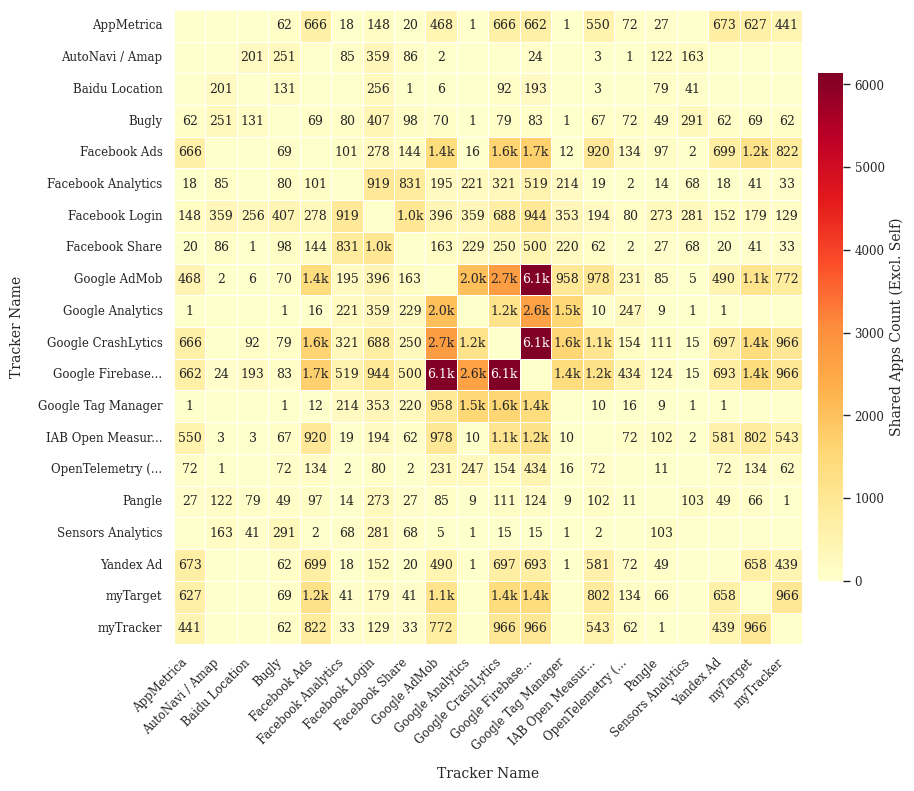

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. SCIENTIFIC PAPER TYPESETTING
# ==========================================
sns.set_theme(style="white", context="paper")
plt.rcParams.update({
    'font.family': 'serif',
    'axes.labelsize': 10,
    'xtick.labelsize': 8.5,
    'ytick.labelsize': 8.5,
    'legend.fontsize': 9
})

# ==========================================
# 2. FILTER & COMPUTE CO-OCCURRENCE
# ==========================================
top_20_trackers = df_trackers_exploded['tracker_names'].value_counts().head(20).index
df_top_a = df_trackers_exploded[df_trackers_exploded['tracker_names'].isin(top_20_trackers)]

app_tracker_matrix = pd.crosstab(df_top_a['_id'].values, df_top_a['tracker_names'].values)
co_occurrence_raw = app_tracker_matrix.T.dot(app_tracker_matrix)

# ==========================================
# 3. OPTIMIZE MATRIX (FULL GRID)
# ==========================================
matrix_values = co_occurrence_raw.to_numpy(copy=True)

# Zero the diagonal so the color scale doesn't blow out
np.fill_diagonal(matrix_values, 0)

co_occurrence = pd.DataFrame(
    matrix_values,
    index=co_occurrence_raw.index,
    columns=co_occurrence_raw.columns
)

# ==========================================
# 4. SHORTEN LABELS & FORMAT NUMBERS
# ==========================================
def shorten_label(name, max_len=18):
    """Truncates long tracker names to keep axes compact."""
    if len(name) > max_len:
        return f"{name[:max_len-3]}..."
    return name

# Overwrite the index and columns with the shortened names
co_occurrence.index = [shorten_label(name) for name in co_occurrence.index]
co_occurrence.columns = [shorten_label(name) for name in co_occurrence.columns]

def format_k(val):
    if val == 0:
        return ""  # Leaves the diagonal completely blank
    elif val >= 1000:
        return f"{val/1000:.1f}k"
    else:
        return str(int(val))

annot_labels = np.vectorize(format_k)(co_occurrence.values)

# ==========================================
# 5. RENDER THE HEATMAP
# ==========================================
plt.figure(figsize=(9.5, 8))

sns.heatmap(
    co_occurrence,
    annot=annot_labels,
    fmt="",
    cmap="YlOrRd",
    annot_kws={"size": 9},        # INCREASED FONT SIZE HERE
    cbar_kws={
        'label': 'Shared Apps Count (Excl. Self)',
        'shrink': 0.8,
        'pad': 0.02
    },
    linewidths=0.5,
    linecolor='white'
)

plt.ylabel("Tracker Name", labelpad=10)
plt.xlabel("Tracker Name", labelpad=10)

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [10]:
open_trackers = df_trackers_exploded[
    df_trackers_exploded['tracker_names'].astype(str).str.startswith("Open")
]['tracker_names'].unique()

print(f"Found {len(open_trackers)} tracker names starting with 'Open':\n")
for tracker in sorted(open_trackers):
    print(f"- {tracker}")

Found 1 tracker names starting with 'Open':

- OpenTelemetry (OpenCensus, OpenTracing)


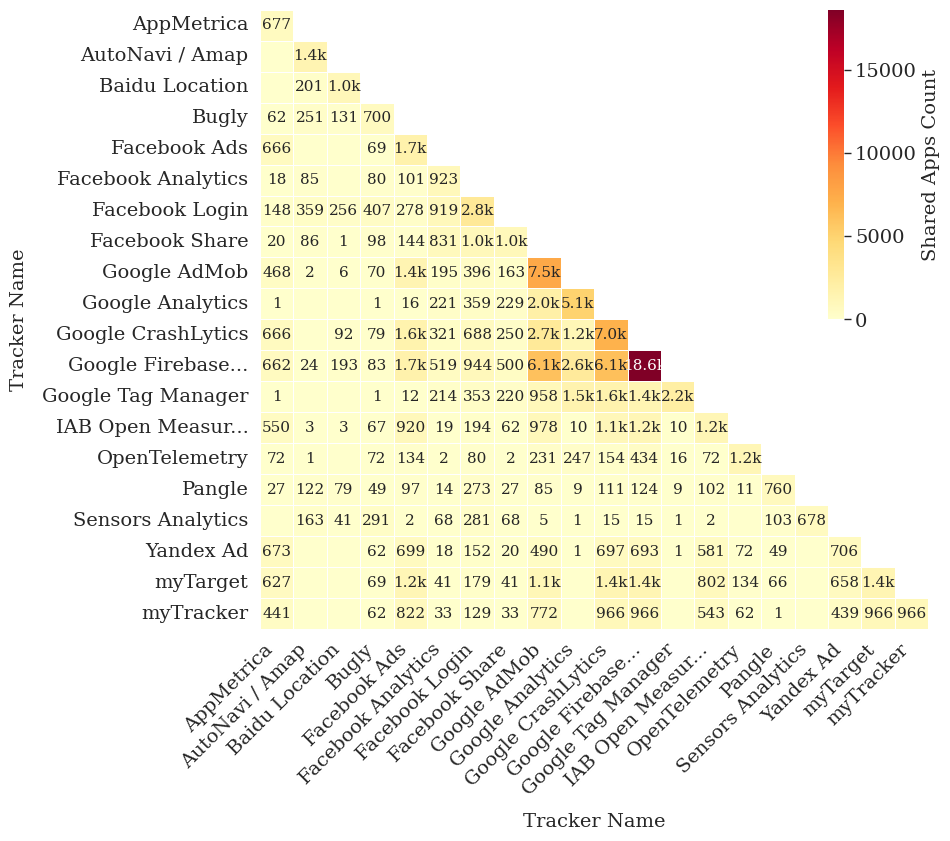

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. SCIENTIFIC PAPER TYPESETTING
# ==========================================
sns.set_theme(style="white", context="paper")
plt.rcParams.update({
    'font.family': 'serif',
    'axes.labelsize': 14,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14
})

# ==========================================
# 2. FILTER & COMPUTE CO-OCCURRENCE
# ==========================================
top_20_trackers = df_trackers_exploded['tracker_names'].value_counts().head(20).index
df_top_a = df_trackers_exploded[df_trackers_exploded['tracker_names'].isin(top_20_trackers)]

app_tracker_matrix = pd.crosstab(df_top_a['_id'].values, df_top_a['tracker_names'].values)
co_occurrence_raw = app_tracker_matrix.T.dot(app_tracker_matrix)

# ==========================================
# 3. KEEP FULL MATRIX & BUILD MASK
# ==========================================
co_occurrence = pd.DataFrame(
    co_occurrence_raw.to_numpy(copy=True),
    index=co_occurrence_raw.index,
    columns=co_occurrence_raw.columns
)

mask = np.triu(np.ones_like(co_occurrence, dtype=bool), k=1)

# ==========================================
# 4. EXPLICIT RENAMING & LABEL SHORTENING
# ==========================================
# --- TARGETED TRACKER RENAME MAP ---
# Add your specific tracker name and its shortened replacement here
tracker_rename_map = {
    "OpenTelemetry (OpenCensus, OpenTracing)": "OpenTelemetry",
}

# Apply explicit renaming to both the index and columns
co_occurrence = co_occurrence.rename(index=tracker_rename_map, columns=tracker_rename_map)

def shorten_label(name, max_len=18):
    if len(name) > max_len:
        return f"{name[:max_len-3]}..."
    return name

# Run fallback truncator for the rest of the 20x20 tracker matrix
co_occurrence.index = [shorten_label(name) for name in co_occurrence.index]
co_occurrence.columns = [shorten_label(name) for name in co_occurrence.columns]

def format_k(val):
    if val == 0:
        return ""
    elif val >= 1000:
        return f"{val/1000:.1f}k"
    else:
        return str(int(val))

annot_labels = np.vectorize(format_k)(co_occurrence.values)

# ==========================================
# 5. RENDER THE COMPLETE TRIANGULAR HEATMAP
# ==========================================
plt.figure(figsize=(9.5, 8.5))

sns.heatmap(
    co_occurrence,
    mask=mask,
    annot=annot_labels,
    fmt="",
    cmap="YlOrRd",
    annot_kws={"size": 11},
    cbar_kws={
        'label': 'Shared Apps Count',
        'shrink': 0.5,
        'pad': -0.15,
        'anchor': (0.0, 1.0)
    },
    linewidths=0.5,
    linecolor='white'
)

plt.ylabel("Tracker Name", labelpad=10)
plt.xlabel("Tracker Name", labelpad=10)

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig("./images/tracker_heatmap.pdf", format='pdf', dpi=300)
plt.show()

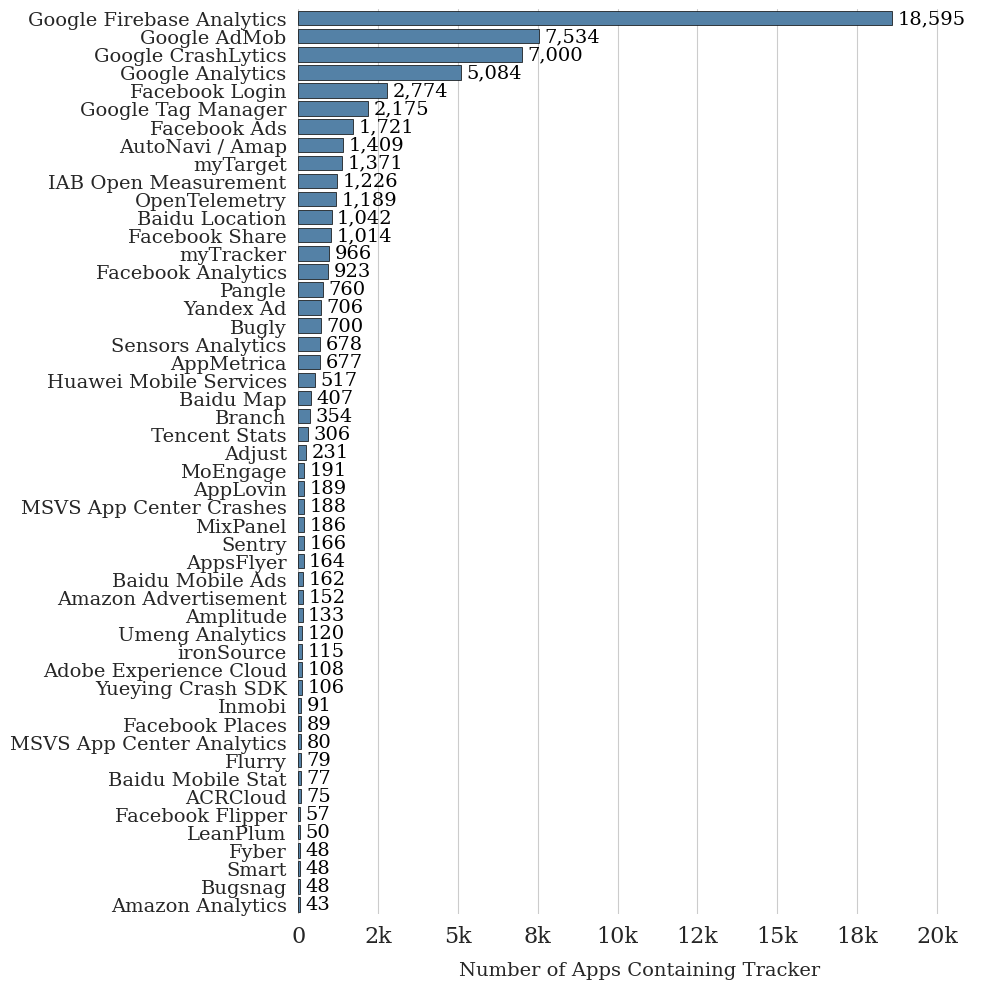

In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ==========================================
# 1. SCIENTIFIC PAPER TYPESETTING
# ==========================================
# Switched to whitegrid to make reading bar lengths easier
sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update({
    'font.family': 'serif',
    'axes.labelsize': 14,
    'xtick.labelsize': 16,
    'ytick.labelsize': 14,
    'axes.titlesize': 16,
})

# ==========================================
# 2. COMPUTE FREQUENCY
# ==========================================
# Adjust this number to show more or fewer trackers
top_n = 50

# Get the counts and convert to a DataFrame for Seaborn
tracker_counts = df_trackers_exploded['tracker_names'].value_counts().head(top_n).reset_index()
tracker_counts.columns = ['Tracker Name', 'App Count']

# ==========================================
# 3. EXPLICIT RENAMING & LABEL SHORTENING
# ==========================================
tracker_rename_map = {
    "OpenTelemetry (OpenCensus, OpenTracing)": "OpenTelemetry",
    "Huawei Mobile Services (HMS) Core": "Huawei Mobile Services",
    "Microsoft Visual Studio App Center Crashes": "MSVS App Center Crashes",
    "AppLovin (MAX and SparkLabs)": "AppLovin",
    "Amazon Analytics (Amazon insights)": "Amazon Analytics",
    "Microsoft Visual Studio App Center Analytics": "MSVS App Center Analytics"
}

# Apply renaming map
tracker_counts['Tracker Name'] = tracker_counts['Tracker Name'].replace(tracker_rename_map)

# Slightly longer max_len since horizontal space is more forgiving than a heatmap grid
def shorten_label(name, max_len=25):
    if len(name) > max_len:
        return f"{name[:max_len-3]}..."
    return name

tracker_counts['Tracker Name'] = tracker_counts['Tracker Name'].apply(shorten_label)

# ==========================================
# 4. RENDER THE HORIZONTAL BAR CHART
# ==========================================
# Height is set to 10 to comfortably fit 50 bars; adjust if you change top_n
plt.figure(figsize=(10, 10))

# Render the bars. A uniform color is standard for ranked frequency plots.
ax = sns.barplot(
    data=tracker_counts,
    x='App Count',
    y='Tracker Name',
    color='steelblue',
    edgecolor='black',
    linewidth=0.5
)

# ADDED: Add value labels to the right of each bar
for container in ax.containers:
    # fmt='{:,.0f}' formats the number with comma separators (e.g., 1,234)
    # padding adds a slight gap between the bar and the text
    ax.bar_label(container, fmt='{:,.0f}', padding=4, fontsize=14, color='black')

# ADDED: Expand the x-axis limit by 15% so the longest labels don't get cut off
max_count = tracker_counts['App Count'].max()
ax.set_xlim(0, max_count * 1.15)

# Format the x-axis to show 'k' for thousands
def format_k_ticks(x, pos):
    if x >= 1000:
        return f'{x*1e-3:.0f}k'
    return str(int(x))

ax.xaxis.set_major_formatter(plt.FuncFormatter(format_k_ticks))

# Labels and Title
plt.xlabel("Number of Apps Containing Tracker", labelpad=10)
plt.ylabel("", labelpad=10) # Removing y-label text as the tracker names are self-explanatory
#plt.title(f"Top {top_n} Most Frequent Trackers", pad=15, fontweight='bold')

# Clean up the plot borders
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.savefig("./images/tracker_frequency_bar.pdf", format='pdf', dpi=300)
plt.show()

In [13]:
# Extract the exact top 30 raw names directly from the source series
top_30_raw_names = df_trackers_exploded['tracker_names'].value_counts().head(100).index.tolist()

print("--- FULL UN-TRUNCATED TRACKER NAMES ---")
for name in top_30_raw_names:
    print(f'"{name}": "",')

--- FULL UN-TRUNCATED TRACKER NAMES ---
"Google Firebase Analytics": "",
"Google AdMob": "",
"Google CrashLytics": "",
"Google Analytics": "",
"Facebook Login": "",
"Google Tag Manager": "",
"Facebook Ads": "",
"AutoNavi / Amap": "",
"myTarget": "",
"IAB Open Measurement": "",
"OpenTelemetry (OpenCensus, OpenTracing)": "",
"Baidu Location": "",
"Facebook Share": "",
"myTracker": "",
"Facebook Analytics": "",
"Pangle": "",
"Yandex Ad": "",
"Bugly": "",
"Sensors Analytics": "",
"AppMetrica": "",
"Huawei Mobile Services (HMS) Core": "",
"Baidu Map": "",
"Branch": "",
"Tencent Stats": "",
"Adjust": "",
"MoEngage": "",
"AppLovin (MAX and SparkLabs)": "",
"Microsoft Visual Studio App Center Crashes": "",
"MixPanel": "",
"Sentry": "",
"AppsFlyer": "",
"Baidu Mobile Ads": "",
"Amazon Advertisement": "",
"Amplitude": "",
"Umeng Analytics": "",
"ironSource": "",
"Adobe Experience Cloud": "",
"Yueying Crash SDK": "",
"Inmobi": "",
"Facebook Places": "",
"Microsoft Visual Studio App Center Analyti

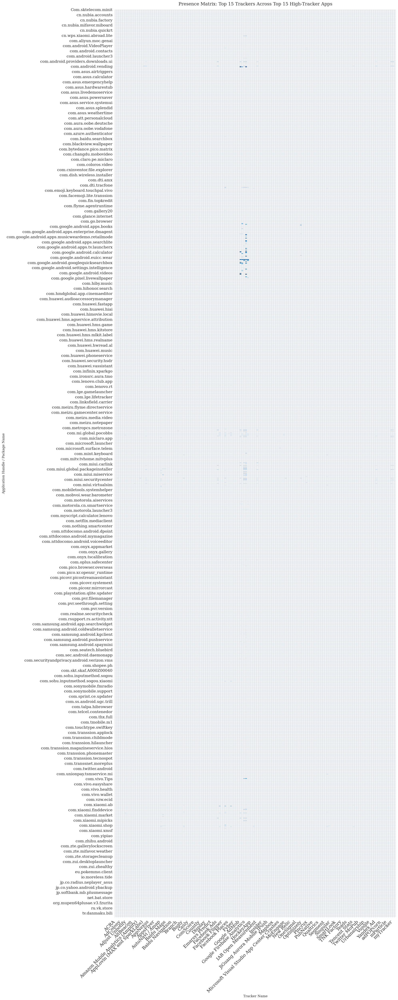

--- Matrix Diagnostic Summary ---
Total entries found in filtered subset: 41328
Matrix Dimensions: 50 Apps x 41 Trackers
Total non-zero matches in matrix: 257

--- Raw Presence Matrix Table ---


tracker_names,ACRCloud,Adjust,Amazon Advertisement,Amplitude,AppLovin (MAX and SparkLabs),AppMetrica,AutoNavi / Amap,Baidu Location,Baidu Map,Baidu Mobile Ads,...,Pangle,Sensors Analytics,Sentry,Tencent Stats,Umeng Analytics,Yandex Ad,Yueying Crash SDK,ironSource,myTarget,myTracker
application.handle,,,,,,,,,,,,,,,,,,,,,
com.android.providers.downloads.ui,0,0,0,0,0,56,0,0,0,0,...,0,0,0,0,0,56,0,0,173,151
com.android.thememanager,0,0,1,0,150,115,0,0,0,0,...,6,0,0,88,0,115,0,0,164,142
com.android.vending,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
com.duokan.phone.remotecontroller,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
com.google.android.GoogleCamera,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
com.google.android.accessibility.soundamplifier,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
com.google.android.apps.maps,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
com.google.android.apps.nbu.files,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
com.google.android.apps.photos,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [14]:
# ==========================================
# OPTION B: APPS VS. TRACKERS PRESENCE HEATMAP
# ==========================================
# Focuses on the top 15 most tracking-heavy apps and the top 15 most frequent trackers.

plt.figure(figsize=(20, 50))

# Find top 15 apps and top 15 trackers
top_15_apps = df_trackers_exploded['application.handle'].value_counts().head(15).index
top_15_trackers = df_trackers_exploded['tracker_names'].value_counts().head(15).index

# Filter the dataset
df_filtered_b = df_trackers_exploded = (df_exodus_final
                        .explode('tracker_names')
                        .dropna(subset=['tracker_names'])
                        .reset_index(drop=True))

# Create cross-tabulation matrix (1 = Present, 0 = Absent)
heatmap_data_b = pd.crosstab(df_filtered_b['application.handle'].values, df_filtered_b['tracker_names'].values)

# Plotting Option B
# We use a distinct color map (Blues) and add light grid lines to make the matrix readable
sns.heatmap(heatmap_data_b, cmap="Blues", linewidths=.7, linecolor='lightgray', cbar=False)
plt.title("Presence Matrix: Top 15 Trackers Across Top 15 High-Tracker Apps", fontsize=16, pad=15)
plt.xlabel("Tracker Name", fontsize=12)
plt.ylabel("Application Handle / Package Name", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ==========================================
# DIAGNOSTIC: PRINT MATRIX DATA FOR OPTION B
# ==========================================

# 1. Recreate the same top 15 cuts
top_15_apps = df_trackers_exploded['application.handle'].value_counts().head(50).index
top_15_trackers = df_trackers_exploded['tracker_names'].value_counts().head(50).index

# 2. Filter the exploded dataframe
df_filtered_diagnostic = df_trackers_exploded[
    df_trackers_exploded['application.handle'].isin(top_15_apps) &
    df_trackers_exploded['tracker_names'].isin(top_15_trackers)
]

# 3. Generate the raw cross-tabulation table
diagnostic_matrix = pd.crosstab(
    df_filtered_diagnostic['application.handle'],
    df_filtered_diagnostic['tracker_names']
)

# 4. Display total data summary stats
print("--- Matrix Diagnostic Summary ---")
print(f"Total entries found in filtered subset: {len(df_filtered_diagnostic)}")
print(f"Matrix Dimensions: {diagnostic_matrix.shape[0]} Apps x {diagnostic_matrix.shape[1]} Trackers")
print(f"Total non-zero matches in matrix: {(diagnostic_matrix > 0).sum().sum()}\n")

# 5. Render the actual DataFrame table in your Jupyter Notebook
print("--- Raw Presence Matrix Table ---")
diagnostic_matrix

In [15]:
import pandas as pd

# 1. Group the exploded data by application.handle
# We add the new fields to the aggregation, pulling the 'first' instance for each app
app_trackers = df_trackers_exploded.groupby('application.handle').agg(
    app_id=('android_app_id_reference', 'first'),
    firmware_id=('firmware_id', 'first'),
    version_detected=('version_detected', 'first'),
    os_vendor=('os_vendor', 'first'),
    total_trackers=('tracker_names', 'nunique'),
    trackers_found=('tracker_names', lambda x: sorted(list(x.dropna().unique())))
).reset_index()

# 2. Filter for default/system Android apps using string prefixes
system_apps_table = app_trackers[
    app_trackers['application.handle'].str.startswith(('com.android.', 'android.'), na=False)
].copy()

# 3. Sort by total_trackers descending so the most heavily tracked apps appear first
system_apps_table = system_apps_table.sort_values(by='total_trackers', ascending=False)

# 4. Clean up the list format for better readability
system_apps_table['trackers_found'] = system_apps_table['trackers_found'].apply(
    lambda x: ", ".join(x) if len(x) > 0 else "None"
)

# Display the summary statistics
print(f"Found {len(system_apps_table)} total system/default Android apps in the dataset.")
print(f"System apps containing at least one tracker: {len(system_apps_table[system_apps_table['total_trackers'] > 0])}")
print("\nTop System Apps to Target for Analysis:")

# Rename columns for a clean table look
display_table = system_apps_table.rename(columns={
    'application.handle': 'Package Name',
    'total_trackers': 'Tracker Count',
    'trackers_found': 'Trackers List'
})

# Reorder the columns to group related information together
display_table = display_table[[
    'Package Name',
    'Tracker Count',
    'Trackers List'
]]

display_table.head(50)

Found 27 total system/default Android apps in the dataset.
System apps containing at least one tracker: 27

Top System Apps to Target for Analysis:


,Package Name,Tracker Count,Trackers List
65,com.android.thememanager,13,"Amazon Advertisement, AppLovin (MAX and SparkL..."
60,com.android.providers.downloads.ui,9,"AppMetrica, Facebook Ads, Google AdMob, Google..."
62,com.android.settings,5,"Display, Google Firebase Analytics, Huawei Mob..."
56,com.android.mms,4,"AutoNavi / Amap, Google CrashLytics, Google Fi..."
44,com.android.browser,4,"Baidu Location, Baidu Mobile Ads, Facebook Log..."
66,com.android.vending,4,"Google AdMob, Google Analytics, Google Firebas..."
48,com.android.contacts,4,"Facebook Login, Google CrashLytics, Google Fir..."
46,com.android.camera,3,"AutoNavi / Amap, Google CrashLytics, Pangle"
64,com.android.systemui,3,"AutoNavi / Amap, Google Firebase Analytics, Op..."
63,com.android.settings.intelligence,3,"Google Firebase Analytics, Microsoft Visual St..."


In [16]:
import pandas as pd

# 1. Group the exploded data by application.handle (Package Name)
# Added filename and the APK path (using absolute_store_path from the previous enrichment,
# or change to 'apk.path' if that is the exact column name in df_trackers_exploded)
all_apps_table = df_trackers_exploded.groupby('application.handle').agg(
    app_id=('android_app_id_reference', 'first'),
    firmware_id=('firmware_id', 'first'),
    filename=('filename', 'first'),
    apk_path=('apk.path', 'first'), # Change to 'apk.path' if needed
    version_detected=('version_detected', 'first'),
    os_vendor=('os_vendor', 'first'),
    total_trackers=('tracker_names', 'nunique'),
    trackers_found=('tracker_names', lambda x: sorted(list(x.dropna().unique())))
).reset_index()

# 2. Sort by total_trackers descending so the most heavily tracked apps appear first
all_apps_table = all_apps_table.sort_values(by='total_trackers', ascending=False)

# 3. Clean up the list format for better readability
all_apps_table['trackers_found'] = all_apps_table['trackers_found'].apply(
    lambda x: ", ".join(x) if len(x) > 0 else "None"
)

# Display the summary statistics
print(f"Found {len(all_apps_table)} total apps in the dataset.")
print(f"Apps containing at least one tracker: {len(all_apps_table[all_apps_table['total_trackers'] > 0])}")

# 4. Rename columns for a clean table look, adding the newly requested fields
display_table = all_apps_table.rename(columns={
    'application.handle': 'Package Name',
    'app_id': 'App ID',
    'firmware_id': 'Firmware ID',
    'filename': 'Filename',
    'apk_path': 'APK.path',
    'total_trackers': 'Tracker Count',
    'trackers_found': 'Trackers List'
})

# 5. Reorder the columns to group related information together
display_table = display_table[[
    'Package Name',
    'App ID',
    'Firmware ID',
    'Filename',
    'APK.path',
    'Tracker Count',
    'Trackers List'
]]

# View the full table
display_table

Found 1055 total apps in the dataset.
Apps containing at least one tracker: 1055


,Package Name,App ID,Firmware ID,Filename,APK.path,Tracker Count,Trackers List
128,com.aura.news.hashtag.news,699890ce0712f939de22e5a3,699891270712f939de22fb56,DishNews.apk,/var/www/file_store/02_file_storage/5fc4d795-3...,28,"AdColony, Amazon Advertisement, AppLovin (MAX ..."
486,com.metropcs.metrozone,6998d8010712f939de45506a,6998d86c0712f939de4564f2,MetroZone.apk,/var/www/file_store/02_file_storage/5fc4d795-3...,28,"AdColony, Amazon Advertisement, AppLovin (MAX ..."
313,com.handmark.expressweather,6998d8080712f939de45517f,6998d86c0712f939de4564f2,TFWeather.apk,/var/www/file_store/02_file_storage/5fc4d795-3...,26,"Amazon Advertisement, Amplitude, AppLovin (MAX..."
29,cn.wps.moffice_eng,6999363c0712f939de67fa9b,699936930712f939de6817ae,NBmoffice.apk,/var/www/file_store/02_file_storage/5fc4d795-3...,22,"Alimama (formerly AdsMogo), Amazon Advertiseme..."
544,com.miui.player,68af83ee65e2ad36cfd42c7a,68af849165e2ad36cfd4a6d0,MIUIMusicGlobal.apk,/var/www/file_store/01_file_storage/dc63ac8b-3...,22,"ACRCloud, Amazon Advertisement, Amplitude, App..."
...,...,...,...,...,...,...,...
738,com.samsung.android.spaymini,699b002b0712f939def19024,699b005b0712f939def1aa85,SamsungPayStubMini.apk,/var/www/file_store/02_file_storage/5fc4d795-3...,1,Google Analytics
737,com.samsung.android.spay,699b70aa0712f939de0f0bed,699b711c0712f939de0f489b,SamsungPayStub.apk,/var/www/file_store/02_file_storage/5fc4d795-3...,1,Google Analytics
736,com.samsung.android.scs,699b14860712f939def792eb,699b14f80712f939def7ace1,SamsungCoreServices.apk,/var/www/file_store/02_file_storage/5fc4d795-3...,1,"OpenTelemetry (OpenCensus, OpenTracing)"
350,com.huawei.hicard,699366c0ef248b310a7a02d3,699367c6ef248b310a7a03f1,HiCard.apk,/var/www/file_store/02_file_storage/5fc4d795-3...,1,Huawei Mobile Services (HMS) Core


In [18]:
import pandas as pd

# 1. Filter the exploded dataframe for system/default apps directly
system_apps = df_trackers_exploded[
    df_trackers_exploded['application.handle'].str.startswith(('com.android.', 'android.'), na=False)
].copy()

# 2. Define the exact columns you want to extract
columns_to_keep = [
    'application.handle',
    'android_app_id_reference',
    "version_detected",
    'firmware_id',
    'filename',
    'absolute_store_path',
    'tracker_names' # Shows the individual tracker for this row
]

# (Safety check to only grab columns that actually exist in the dataframe)
available_columns = [col for col in columns_to_keep if col in system_apps.columns]
system_apps = system_apps[available_columns]

# 3. Rename columns for a clean table look
display_table = system_apps.rename(columns={
    'application.handle': 'Package Name',
    'android_app_id_reference': 'App ID',
    "version_detected": "Android Version",
    'firmware_id': 'Firmware ID',
    'filename': 'Filename',
    'absolute_store_path': 'APK.path',
    'tracker_names': 'Tracker Name'
})

# OPTIONAL: If you only want each package listed exactly once (ignoring multiple trackers),
# uncomment the following line:
# display_table = display_table.drop_duplicates(subset=['Package Name'])

# 4. Sort the table alphabetically by Package Name
display_table = display_table.sort_values(by='Package Name')

print(f"Found {len(display_table)} tracker entries for system/default Android apps.")

#print(f"Number of unique system apps with at least one tracker: {unique_app_count}")
# Displa
display_table

Found 5818 tracker entries for system/default Android apps.


,Package Name,App ID,Android Version,Firmware ID,Filename,Tracker Name
62223,com.android.VideoPlayer,699bdc500712f939de3b2cc1,12,699bdce90712f939de3b89a8,VideoPlayer.apk,Pangle
62222,com.android.VideoPlayer,699bdc500712f939de3b2cc1,12,699bdce90712f939de3b89a8,VideoPlayer.apk,Google AdMob
56454,com.android.bluetooth,6999b5030712f939de95cf5f,14,6999b5ab0712f939de961c22,Bluetooth.apk,Pangle
58692,com.android.browser,699add400712f939dedfd464,14,699add590712f939dedfda39,MIUIBrowser.apk,Facebook Login
3314,com.android.browser,68b117f665e2ad36cf153fc4,12,68b1187e65e2ad36cf157cea,MiBrowser.apk,Baidu Location
3313,com.android.browser,68b117f665e2ad36cf153fc4,12,68b1187e65e2ad36cf157cea,MiBrowser.apk,Facebook Login
58707,com.android.browser,699ac4580712f939ded85a44,15,699ac4720712f939ded85f0b,MIUIBrowser.apk,Facebook Login
14079,com.android.browser,699ae04f0712f939dee15c4b,12,699ae0c70712f939dee1abb2,MiBrowser.apk,Baidu Location
14080,com.android.browser,699ae04f0712f939dee15c4b,12,699ae0c70712f939dee1abb2,MiBrowser.apk,Pangle
19717,com.android.browser,68b054e865e2ad36cf7fa8c0,13,68b0552065e2ad36cf7fb511,MIUIBrowser.apk,Facebook Login


In [19]:
# 1. Total tracker entries found (absolute number of rows in your table)
total_tracker_entries = len(display_table)
print(f"Absolute number of tracker entries found: {total_tracker_entries}")

# 2. Number of unique system apps that have AT LEAST one tracker
unique_tracked_apps = display_table['Package Name'].nunique()
print(f"Number of system apps (unique package names) with at least one tracker: {unique_tracked_apps}")

# Extract unique combinations of Filename and Package Name
unique_files_and_packages = display_table.drop_duplicates(subset=['Filename', 'Package Name'])

print(f"Found {len(unique_files_and_packages)} unique Filename & Package Name combinations:\n")

# Loop through the unique rows and print both columns together
for index, row in unique_files_and_packages.iterrows():
    print(f"File: {row['Filename']}  -->  Package: {row['Package Name']}")

Absolute number of tracker entries found: 5818
Number of system apps (unique package names) with at least one tracker: 27
Found 61 unique Filename & Package Name combinations:

File: VideoPlayer.apk  -->  Package: com.android.VideoPlayer
File: Bluetooth.apk  -->  Package: com.android.bluetooth
File: MIUIBrowser.apk  -->  Package: com.android.browser
File: MiBrowser.apk  -->  Package: com.android.browser
File: Browser.apk  -->  Package: com.android.browser
File: MIUIBrowserPad.apk  -->  Package: com.android.browser
File: FlymeCalendar.apk  -->  Package: com.android.calendar
File: MiuiCamera.apk  -->  Package: com.android.camera
File: NubiaCamera.apk  -->  Package: com.android.camera
File: VivoCamera.apk  -->  Package: com.android.camera
File: NothingCompanionDeviceManager.apk  -->  Package: com.android.companiondevicemanager
File: MIUIContactsT.apk  -->  Package: com.android.contacts
File: MIUIContacts.apk  -->  Package: com.android.contacts
File: DCMContacts.apk  -->  Package: com.andr

In [20]:
# Define a tuple of interesting non-AOSP system prefixes
oem_prefixes = (
    # --- Google / Core Services ---
    'com.google.android.',

    # --- Chipsets / Hardware (SoCs) ---
    'com.qualcomm.',          # Snapdragon
    'com.mediatek.',          # MediaTek (Modern)
    'com.mtk.',               # MediaTek (Legacy)
    'com.spreadtrum.',        # Unisoc/Spreadtrum (Budget devices)
    'com.unisoc.',            # Unisoc
    'com.hisilicon.',         # Huawei Kirin chips
    'com.nvidia.',            # Nvidia Tegra (Tablets/Shield)
    'com.intel.',             # Legacy Android x86 devices

    # --- Samsung ---
    'com.samsung.',           # General Samsung apps
    'com.sec.',               # Samsung Electronics Co. (Core system apps)
    'com.sec.android.',       # Samsung Android extensions

    # --- Xiaomi / POCO / Redmi ---
    'com.xiaomi.',            # Base Xiaomi
    'com.miui.',              # Xiaomi's custom Android skin
    'com.mi.',                # Miscellaneous Xiaomi services

    # --- Huawei / Honor ---
    'com.huawei.',
    'com.honor.',
    'com.hihonor.',

    # --- BBK Electronics (Oppo, Vivo, OnePlus, Realme) ---
    'com.oppo.',
    'com.oplus.',             # Unified Oppo/OnePlus codebase
    'com.coloros.',           # Oppo's custom Android skin
    'com.vivo.',
    'com.iqoo.',              # Vivo sub-brand
    'com.bbk.',               # Parent company legacy apps
    'com.oneplus.',
    'com.realme.',

    # --- Motorola / Lenovo ---
    'com.motorola.',
    'com.lenovo.',
    'com.zui.',               # Lenovo's custom Android skin

    # --- Sony ---
    'com.sony.',
    'com.sonyericsson.',      # Legacy Sony system apps (still present on modern devices)
    'com.sonymobile.',

    # --- LG (Discontinued but heavily present in older datasets) ---
    'com.lge.',

    # --- Asus ---
    'com.asus.',

    # --- Nokia / HMD Global ---
    'com.hmdglobal.',
    'com.evenwell.',          # Notorious 3rd-party system management apps bundled on Nokia devices

    # --- ZTE / HTC / Meizu / TCL ---
    'com.zte.',
    'com.nubia.',             # ZTE sub-brand
    'com.htc.',
    'com.meizu.',
    'com.flyme.',             # Meizu's custom Android skin
    'com.tcl.',
    'com.alcatel.',

    # --- Transsion (Massive in African, South Asian, & South American markets) ---
    'com.transsion.',
    'com.tecno.',
    'com.infinix.',
    'com.itel.',

    # --- US Carriers ---
    'com.vzw.',               # Verizon
    'com.tmobile.',           # T-Mobile
    'com.att.',               # AT&T
    'com.sprint.',            # Sprint (Legacy but present)
    'com.uscc.',              # US Cellular

    # --- European / Global Carriers ---
    'com.vodafone.',
    'com.orange.',
    'com.telefonica.',
    'com.o2.',
    'com.ee.',

    # --- Canadian Carriers ---
    'com.telus.',
    'com.bell.',
    'com.rogers.'
)

# Filter the app_trackers dataframe (from the previous step)
oem_apps_table = app_trackers[
    app_trackers['application.handle'].str.startswith(oem_prefixes, na=False)
].copy()

# Sort by the most heavily tracked apps
oem_apps_table = oem_apps_table.sort_values(by='total_trackers', ascending=False)

# Clean up the format
oem_apps_table['trackers_found'] = oem_apps_table['trackers_found'].apply(
    lambda x: ", ".join(x) if len(x) > 0 else "None"
)

# Rename and display
display_oem_table = oem_apps_table.rename(columns={
    'firmware_id': 'Firmware ID',
    'version_detected': 'Android Version',
    'app_id': 'App ID',
    'application.handle': 'Package Name',
    'total_trackers': 'Tracker Count',
    'trackers_found': 'Trackers List'
})[['Firmware ID', 'Android Version', 'App ID', 'Package Name', 'Tracker Count', 'Trackers List']]

print(f"Found {len(display_oem_table)} OEM/Hardware apps in the dataset.")
display_oem_table.head(100)

Found 530 OEM/Hardware apps in the dataset.


,Firmware ID,Android Version,App ID,Package Name,Tracker Count,Trackers List
544,68af849165e2ad36cfd4a6d0,12,68af83ee65e2ad36cfd42c7a,com.miui.player,22,"ACRCloud, Amazon Advertisement, Amplitude, AppLovin (MAX and SparkLabs), AppMetrica, AppMonet, Bugly, Facebook Ads, Facebook Login, Fyber, Google AdMob, Google CrashLytics, Google Firebase Analytics, IAB Open Measurement, MixPanel, MoEngage, OpenTelemetry (OpenCensus, OpenTracing), Pangle, Yandex Ad, ironSource, myTarget, myTracker"
550,68af849165e2ad36cfd4a6d0,12,68af83e465e2ad36cfd425b7,com.miui.videoplayer,16,"Amazon Advertisement, AppMetrica, AppMonet, Facebook Ads, Facebook Analytics, Facebook Login, Facebook Share, Google AdMob, Google CrashLytics, Google Firebase Analytics, IAB Open Measurement, Pangle, Unity3d Ads, Yandex Ad, myTarget, myTracker"
495,68af849165e2ad36cfd4a6d0,12,68af83e865e2ad36cfd428d0,com.mi.globalbrowser,15,"AppMetrica, AppMonet, Facebook Ads, Facebook Analytics, Facebook Login, Facebook Places, Facebook Share, Google AdMob, Google CrashLytics, Google Firebase Analytics, IAB Open Measurement, Pangle, Yandex Ad, myTarget, myTracker"
178,6999d9e60712f939dea8b746,13,6999d9640712f939dea865d5,com.coloros.filemanager,15,"Amazon Advertisement, AppLovin (MAX and SparkLabs), AppMetrica, AppMonet, Facebook Ads, Google AdMob, Google CrashLytics, Google Firebase Analytics, IAB Open Measurement, Pangle, Vungle, Yandex Ad, ironSource, myTarget, myTracker"
573,6998972d0712f939de263b0a,13,6998967d0712f939de25d277,com.motorola.ccc.notification,13,"Amazon Advertisement, AppLovin (MAX and SparkLabs), Facebook Ads, Fyber, Google AdMob, Google Firebase Analytics, IAB Open Measurement, Inmobi, MoEngage, Pangle, Sentry, Vungle, ironSource"
949,68af219965e2ad36cf8260b2,12,68af203765e2ad36cf815f6a,com.xiaomi.smarthome,12,"AutoNavi / Amap, Bugly, Facebook Analytics, Facebook Login, Facebook Places, Facebook Share, Google Firebase Analytics, Huawei Mobile Services (HMS) Core, MixPanel, Pangle, Sensors Analytics, Tencent Stats"
529,68af849165e2ad36cfd4a6d0,12,68af83eb65e2ad36cfd42adb,com.miui.cleaner,11,"AppMetrica, AppMonet, Facebook Ads, Google AdMob, Google CrashLytics, Google Firebase Analytics, IAB Open Measurement, Pangle, Yandex Ad, myTarget, myTracker"
643,6999d9e60712f939dea8b746,13,6999d96f0712f939dea86dd0,com.oppo.quicksearchbox,10,"Amazon Advertisement, AppLovin (MAX and SparkLabs), Branch, Facebook Ads, Google AdMob, Google CrashLytics, Google Firebase Analytics, IAB Open Measurement, Vungle, myTarget"
532,68af849165e2ad36cfd4a6d0,12,68af83e965e2ad36cfd42975,com.miui.fm,10,"AutoNavi / Amap, Baidu Mobile Ads, Bugly, Facebook Login, Google CrashLytics, Google Firebase Analytics, Huawei Mobile Services (HMS) Core, Pangle, Umeng Analytics, Yueying Crash SDK"
534,68af527e65e2ad36cfab0359,12,68af505f65e2ad36cfa96585,com.miui.global.packageinstaller,10,"AppMetrica, Facebook Ads, Google AdMob, Google CrashLytics, Google Firebase Analytics, IAB Open Measurement, Pangle, Yandex Ad, myTarget, myTracker"


In [21]:
import pandas as pd

# 1. Ensure we filter the raw exploded dataset using your pre-defined OEM prefixes
# This preserves the raw rows (one per tracker per file) so we can group cleanly
df_oem_raw = df_trackers_exploded[
    df_trackers_exploded['application.handle'].str.startswith(oem_prefixes, na=False)
].copy()

# 2. Group by BOTH 'application.handle' and 'filename' (and optionally 'firmware_id' if tracked)
# This gives you the tracker count *per unique file instance*
oem_file_breakdown = df_oem_raw.groupby(['application.handle', 'filename']).agg(
    firmware_id=('firmware_id', 'first'),
    android_version=('version_detected', 'first'),
    apk_path=('apk.path', 'first'), # Fallback to 'apk.path' if needed
    tracker_count=('tracker_names', 'nunique'),
    trackers_list=('tracker_names', lambda x: ", ".join(sorted(list(x.dropna().unique()))) if x.dropna().nunique() > 0 else "None")
).reset_index()

# 3. Sort by Tracker Count descending, then by Package Name
oem_file_breakdown = oem_file_breakdown.sort_values(by=['tracker_count', 'application.handle'], ascending=[False, True])

# 4. Clean up column names for the display table
display_oem_files = oem_file_breakdown.rename(columns={
    'application.handle': 'Package Name',
    'filename': 'Filename',
    'firmware_id': 'Firmware ID',
    'android_version': 'Android Version',
    'absolute_store_path': 'APK.path',
    'tracker_count': 'Tracker Count',
    'trackers_list': 'Trackers List'
})

# Reorder columns to focus heavily on Package, File, and Tracker numbers
display_oem_files = display_oem_files[[
    'Package Name',
    'Filename',
    'Tracker Count',
    'Trackers List',
    'Firmware ID',
    'Android Version'
]]

# Summary Statistics
print(f"Total unique OEM package/file combinations: {len(display_oem_files)}")
print(f"OEM files containing at least 1 tracker: {len(display_oem_files[display_oem_files['Tracker Count'] > 0])}")

# View the full table (or use .head(100) if it's massive)
display_oem_files

Total unique OEM package/file combinations: 733
OEM files containing at least 1 tracker: 733


,Package Name,Filename,Tracker Count,Trackers List,Firmware ID,Android Version
428,com.miui.player,MIUIMusicGlobal.apk,21,"Amazon Advertisement, Amplitude, AppLovin (MAX and SparkLabs), AppMetrica, AppMonet, Bugly, Facebook Ads, Facebook Login, Fyber, Google AdMob, Google CrashLytics, Google Firebase Analytics, IAB Open Measurement, MixPanel, MoEngage, OpenTelemetry (OpenCensus, OpenTracing), Pangle, Yandex Ad, ironSource, myTarget, myTracker",68af849165e2ad36cfd4a6d0,12
447,com.miui.videoplayer,MIUIVideoPlayer.apk,16,"Amazon Advertisement, AppMetrica, AppMonet, Facebook Ads, Facebook Analytics, Facebook Login, Facebook Share, Google AdMob, Google CrashLytics, Google Firebase Analytics, IAB Open Measurement, Pangle, Unity3d Ads, Yandex Ad, myTarget, myTracker",68af849165e2ad36cfd4a6d0,12
368,com.mi.globalbrowser,MIBrowserGlobal_removable.apk,15,"AppMetrica, AppMonet, Facebook Ads, Facebook Analytics, Facebook Login, Facebook Places, Facebook Share, Google AdMob, Google CrashLytics, Google Firebase Analytics, IAB Open Measurement, Pangle, Yandex Ad, myTarget, myTracker",68af533165e2ad36cfab8ee0,12
63,com.coloros.filemanager,FileManagerPU.apk,14,"Amazon Advertisement, AppLovin (MAX and SparkLabs), AppMetrica, AppMonet, Facebook Ads, Google AdMob, Google CrashLytics, Google Firebase Analytics, IAB Open Measurement, Pangle, Yandex Ad, ironSource, myTarget, myTracker",699a18330712f939dec19b35,14
429,com.miui.player,MIUIMusicGlobalPad.apk,14,"Amplitude, AppMetrica, Facebook Ads, Facebook Login, Google AdMob, Google CrashLytics, Google Firebase Analytics, IAB Open Measurement, MixPanel, MoEngage, OpenTelemetry (OpenCensus, OpenTracing), Pangle, Yandex Ad, myTarget",68af631a65e2ad36cfb9ff0d,13
366,com.mi.globalbrowser,MIBrowserGlobal.apk,13,"AppMetrica, Facebook Ads, Facebook Analytics, Facebook Login, Facebook Places, Facebook Share, Google AdMob, Google CrashLytics, Google Firebase Analytics, IAB Open Measurement, Yandex Ad, myTarget, myTracker",68af849165e2ad36cfd4a6d0,12
367,com.mi.globalbrowser,MIBrowserGlobal_builtin_before_2021.apk,13,"AppMetrica, Facebook Ads, Facebook Analytics, Facebook Login, Facebook Places, Facebook Share, Google AdMob, Google CrashLytics, Google Firebase Analytics, IAB Open Measurement, Yandex Ad, myTarget, myTracker",68af98bd65e2ad36cfe66784,13
460,com.motorola.ccc.notification,3c_notification.apk,13,"Amazon Advertisement, AppLovin (MAX and SparkLabs), Facebook Ads, Fyber, Google AdMob, Google Firebase Analytics, IAB Open Measurement, Inmobi, MoEngage, Pangle, Sentry, Vungle, ironSource",6998972d0712f939de263b0a,13
693,com.xiaomi.smarthome,SmartHome.apk,12,"AutoNavi / Amap, Bugly, Facebook Analytics, Facebook Login, Facebook Places, Facebook Share, Google Firebase Analytics, Huawei Mobile Services (HMS) Core, MixPanel, Pangle, Sensors Analytics, Tencent Stats",68af219965e2ad36cf8260b2,12
384,com.miui.cleaner,MIUICleanMasterGlobal-cleaner.apk,11,"AppMetrica, AppMonet, Facebook Ads, Google AdMob, Google CrashLytics, Google Firebase Analytics, IAB Open Measurement, Pangle, Yandex Ad, myTarget, myTracker",68af719265e2ad36cfc51bcd,12


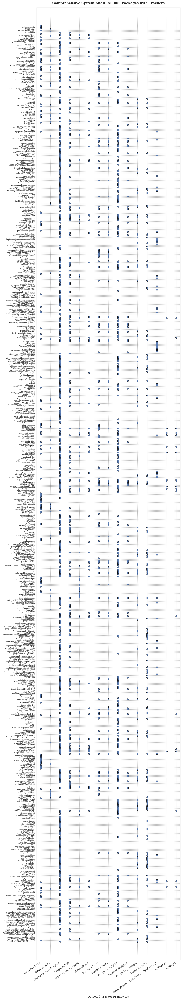

In [22]:
# ==========================================
# 1. REBUILD THE MATRIX WITH A WIDER FILTER
# ==========================================

# Instead of picking the top 20, let's grab EVERY system/OEM app
# that has at least one tracker in our dataset
apps_with_trackers = df_trackers_exploded['application.handle'].unique()

# Keep the tracker filter focused on the top 15 most frequent overall
# to keep the X-axis from blowing up
top_trackers = df_trackers_exploded['tracker_names'].value_counts().head(15).index

# Filter the data
df_plot_expanded = df_trackers_exploded[
    df_trackers_exploded['application.handle'].isin(apps_with_trackers) &
    df_trackers_exploded['tracker_names'].isin(top_trackers)
]

# Create the expanded matrix
matrix_expanded = pd.crosstab(
    df_plot_expanded['application.handle'].values,
    df_plot_expanded['tracker_names'].values
).clip(upper=1)


# ==========================================
# 2. GENERATE THE NEW COMPACT DOT PLOT
# ==========================================

# Melt the new expanded matrix
df_flat_exp = matrix_expanded.reset_index(names='Package Name')
df_melted_exp = df_flat_exp.melt(
    id_vars='Package Name',
    var_name='Tracker Name',
    value_name='Presence'
)

# Only keep rows where a tracker is present
df_melted_exp = df_melted_exp[df_melted_exp['Presence'] == 1]

# Optional clean-up function to shorten package namespaces for Y-ticks
def clean_package_name(pkg, max_len=35):
    # Remove common prefixes to make the text vastly narrower
    for prefix in ["com.", "org.", "net."]:
        if pkg.startswith(prefix):
            pkg = pkg[len(prefix):]
    if len(pkg) > max_len:
        return f"...{pkg[-(max_len-3):]}"
    return pkg

df_melted_exp['Clean Package Name'] = df_melted_exp['Package Name'].apply(clean_package_name)

# Sort alphabetically using the cleaned names
df_melted_exp = df_melted_exp.sort_values(by='Clean Package Name', ascending=False)

num_apps = df_melted_exp['Clean Package Name'].nunique()

# --- OPTIMIZED DIMENSIONING ---
# We cap the height at 12 inches. If there are few apps, it shrinks, but it will never "blow up"
fig_height = min(60.0, max(6.0, num_apps * 10))
# Adjust dot scale dynamically so dots shrink slightly if you have many apps
dot_size = max(50, min(180, 4000 / num_apps))
# Adjust y-tick font size so smaller heights don't cause text overlapping
y_font_size = max(7, min(11, 300 / num_apps))

plt.figure(figsize=(11, fig_height))

# Plotting with the cleaned, shorter package names on the Y-axis
sns.scatterplot(
    data=df_melted_exp,
    x='Tracker Name',
    y='Clean Package Name',
    s=dot_size,
    color='#4C72B0',
    alpha=0.9,
    edgecolor='black',
    linewidth=0.8
)

plt.title(f"Comprehensive System Audit: All {num_apps} Packages with Trackers", fontsize=14, pad=15, fontweight='bold')
plt.xlabel("Detected Tracker Framework", fontsize=12, labelpad=8)
plt.ylabel("", labelpad=5) # Removing 'Package Namespace' label to save precious horizontal space

# Clean grid styling
plt.grid(True, axis='both', linestyle=':', alpha=0.5, color='gray')

# Style the ticks cleanly
plt.xticks(rotation=35, ha='right', fontsize=10)
plt.yticks(fontsize=y_font_size)

# Tighten plot margins
plt.gca().margins(x=0.03, y=0.02)

plt.tight_layout()
plt.savefig("./images/compact_system_audit.pdf", format='pdf', dpi=300, bbox_inches='tight')
plt.show()




In [23]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import math

# ==========================================
# 1. PREPROCESS & GROUP DATA BY PREFIX
# ==========================================
df_flat = matrix_expanded.reset_index(names='Package Name')
df_melted = df_flat.melt(id_vars='Package Name', var_name='Tracker Name', value_name='Presence')
df_active = df_melted[df_melted['Presence'] == 1].copy()

def get_prefix(package_string):
    parts = package_string.split('.')
    return f"{parts[0]}.{parts[1]}" if len(parts) >= 2 else package_string

df_active['Package Prefix'] = df_active['Package Name'].apply(get_prefix)

df_counts = df_active.groupby(['Tracker Name', 'Package Prefix']).size().reset_index(name='App Count')
df_counts = df_counts.sort_values(by=['Tracker Name', 'App Count'], ascending=[True, False])

# ==========================================
# 2. SETUP DYNAMIC HEIGHT RATIOS WITH GRIDSPEC
# ==========================================
trackers = df_counts['Tracker Name'].unique()
num_trackers = len(trackers)

num_cols = 3
num_rows = math.ceil(num_trackers / num_cols)

# Step A: Calculate how many unique categories are in each row of our layout
# We group trackers into rows of 3 to determine how much space that row needs
row_heights = []
for r in range(num_rows):
    row_trackers = trackers[r*num_cols : (r+1)*num_cols]
    # Find the maximum number of items any tracker in this row has
    max_items_in_row = max([df_counts[df_counts['Tracker Name'] == t]['Package Prefix'].nunique() for t in row_trackers] + [1])
    row_heights.append(max_items_in_row)

# Step B: Dynamically scale the total figure height based on the cumulative rows
# 0.25 inches per bar ensures text remains clear and un-squished
total_fig_height = sum(row_heights) * 0.25 + (num_rows * 1.5)

fig = plt.figure(figsize=(18, total_fig_height))

# Create a grid where rows scale in size perfectly matching row_heights
gs = gridspec.GridSpec(num_rows, num_cols, height_ratios=row_heights)

# ==========================================
# 3. POPULATE INDIVIDUAL PLOTS WITH DYNAMIC SCALE
# ==========================================
for i, tracker in enumerate(trackers):
    # Determine grid coordinates
    row_idx = i // num_cols
    col_idx = i % num_cols

    # Initialize the subplot inside our variable-height grid
    ax = fig.add_subplot(gs[row_idx, col_idx])

    tracker_data = df_counts[df_counts['Tracker Name'] == tracker]
    num_items = len(tracker_data)

    sns.barplot(
        data=tracker_data,
        x='App Count',
        y='Package Prefix',
        ax=ax,
        color='#4C72B0',
        edgecolor='black',
        linewidth=0.5
    )

    # Calculate an optimal font size dynamically so long list profiles stay readable
    y_font = max(6, min(11, 120 / max(1, num_items)))

    # Aesthetics per subplot
    ax.set_title(f"Tracker: {tracker} ({num_items} Prefixes)", fontsize=12, fontweight='bold', pad=8)
    ax.set_xlabel("", fontsize=10)
    ax.set_ylabel("", fontsize=10)
    ax.grid(True, axis='x', linestyle='--', alpha=0.5)
    ax.tick_params(axis='y', labelsize=y_font)
    sns.despine(ax=ax, left=True, bottom=True)

# Global layout settings
fig.supxlabel('Number of Apps Infested', fontsize=14, y=0.005)

# h_pad adds extra breathing space vertically between rows of different scales
plt.tight_layout(h_pad=2.5, w_pad=2.0)
plt.savefig("./images/individual_trackers_dynamic_grid.pdf", format='pdf', dpi=300, bbox_inches='tight')
plt.show()




In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. GENERATE THE SWAPPED DOT PLOT
# ==========================================

# Determine figure width dynamically based on the number of unique apps
# This ensures that long lists of package names stretch out horizontally and stay legible
num_apps = df_melted_exp['Package Name'].nunique()
fig_width = max(12, num_apps * 0.4)

plt.figure(figsize=(fig_width, 10))

sns.scatterplot(
    data=df_melted_exp,
    x='Package Name',     # Mapped to X-Axis
    y='Tracker Name',     # Mapped to Y-Axis
    s=180,
    color='#4C72B0',
    alpha=0.9,
    edgecolor='black'
)

plt.title(f"Comprehensive System Audit: All {num_apps} System/OEM Packages with Trackers", fontsize=16, pad=20)
plt.xlabel("Package Namespace (Alphabetically Ordered)", fontsize=12, labelpad=10)
plt.ylabel("Detected Tracker Framework", fontsize=12, labelpad=10)

# Add background structural gridlines
plt.grid(True, axis='both', linestyle='--', alpha=0.4, color='gray')

# Rotate the package names 90 degrees so they line up cleanly under their dots
plt.xticks(rotation=90, ha='center', fontsize=10)
plt.yticks(fontsize=11)

plt.tight_layout()
plt.show()

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt

# ==========================================
# 1. SETUP THE DATA AND COMPONENT ORDERING
# ==========================================

# Ensure the package names are sorted alphabetically for consistent alignment across subplots
df_melted_exp = df_melted_exp.sort_values(by='Package Name')

# Get a unique list of trackers and packages to ensure a clean grid alignment
unique_trackers = sorted(df_melted_exp['Tracker Name'].unique())
unique_packages = sorted(df_melted_exp['Package Name'].unique())

# Calculate dynamic grid sizing
num_trackers = len(unique_trackers)
num_cols = 1  # Stack them vertically for perfect scanning of long horizontal package lists
num_rows = num_trackers

# Dynamic figure size adjustment based on dataset dimensions
fig_width = max(14, len(unique_packages) * 0.35)
fig_height = num_rows * 2.5  # Give each subplot comfortable vertical breathing room

# ==========================================
# 2. GENERATE THE SUBPLOT GRID (FACETGRID)
# ==========================================

# Initialize the multi-plot grid structure
g = sns.FacetGrid(
    df_melted_exp,
    col="Tracker Name",
    col_wrap=num_cols,
    height=2.5,
    aspect=fig_width / 2.5,
    sharex=True,     # Keeps the identical X-axis labels on the very bottom plot
    sharey=False
)

# Map a custom scatter plot onto each grid cell
g.map_dataframe(
    sns.scatterplot,
    x='Package Name',
    y='Tracker Name', # Using the name as a fixed Y anchor so dots sit on a clean horizontal line
    s=140,
    color='#4C72B0',
    alpha=0.9,
    edgecolor='black'
)

# ==========================================
# 3. POLISH AND FORMAT GRAPH INTERFACES
# ==========================================

# Apply styling parameters to every individual subplot axis
for ax in g.axes.flatten():
    # Add light background structural lines to track points over long package strings
    ax.grid(True, axis='x', linestyle='--', alpha=0.3, color='gray')
    ax.set_ylabel("", visible=False) # Hide redundant inner Y labels
    ax.tick_params(axis='y', left=False, labelleft=False) # Clear out the blank category tick marks

    # Extract the dynamic subplot title and format it into a bold clean banner
    current_title = ax.get_title().split(" = ")[-1]
    ax.set_title(f"Tracker Profile: {current_title}", fontsize=12, weight='bold', loc='left', pad=8)

# Set global structural layout descriptions
g.set_axis_labels("", "")
g.fig.suptitle(
    f"Multi-Tracker Fingerprint Analysis Across {len(unique_packages)} Infected System/OEM Packages",
    fontsize=16,
    weight='bold',
    y=1.02
)

# Rotate the package labels on the bottom-most axis so they read perfectly underneath the columns
plt.xticks(rotation=90, ha='center', fontsize=9)

# Render layout frames
plt.tight_layout()
plt.show()

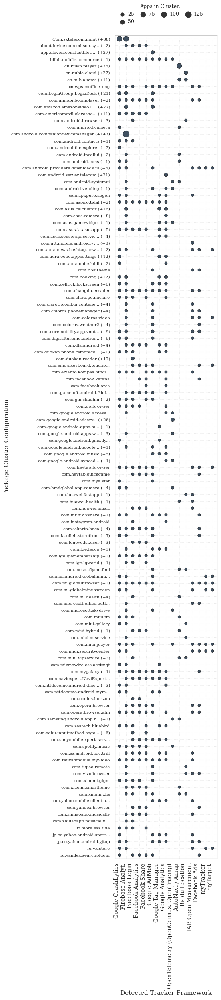

In [26]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Compact academic typesetting configuration
sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update({
    'font.family': 'serif',
    'axes.labelsize': 11,       # Increased for scannability
    'xtick.labelsize': 10,      # High visibility on small scale
    'ytick.labelsize': 7.5,       # Slightly smaller for long names
    'legend.fontsize': 9,
    'legend.title_fontsize': 9
})

# 1. GENERATE CONDENSED MATRIX WITH FIXED 1D FINGERPRINTS
fingerprints = matrix_expanded.astype(str).agg(''.join, axis=1)
df_grouped = matrix_expanded.groupby(fingerprints)

df_condensed = df_grouped.first()
counts = df_grouped.size()

df_meta = pd.DataFrame({
    'rep_app': [g[0] for g in df_grouped.groups.values()],
    'count': counts.values
}, index=df_condensed.index)

# Sort alphabetically by raw app name (ascending=False ensures 'A' is at the top)
df_meta = df_meta.sort_values(by='rep_app', ascending=False)
df_condensed = df_condensed.loc[df_meta.index]

# --- MODIFIED TRUNCATION RULE FOR TARGET ANALYSIS SYSTEM PACKAGES ---
def truncate_package_label(rep_app, cluster_count, max_len=25):
    """Truncates long package IDs but preserves com.android.* targets completely."""
    clean_app = str(rep_app)

    # SYSTEM BYPASS: If the package belongs to the target system frame, skip truncation
    if clean_app.startswith("com.android."):
        pass
    elif len(clean_app) > max_len:
        clean_app = f"{clean_app[:max_len]}..."

    return f"{clean_app} (+{cluster_count-1})" if cluster_count > 1 else clean_app

# Create tight, scannable labels line-by-line
df_condensed['Package Configuration'] = [
    truncate_package_label(row['rep_app'], row['count'], max_len=25)
    for _, row in df_meta.iterrows()
]
df_condensed['App Count'] = df_meta['count'].values

# 2. MELT & MINIMALIST PUBLICATION PLOT
df_melted = df_condensed.melt(
    id_vars=['Package Configuration', 'App Count'],
    var_name='Tracker Name', value_name='Presence'
)
df_melted = df_melted[df_melted['Presence'] == 1].sort_values('Package Configuration')

# --- CRITICAL FIX: SHORTEN SPECIFIC LONG X-LABELS ---
# Define an explicit mapping for your longest tracker framework names
tracker_rename_map = {
    "Huawei Mobile Services (HMS) Core": "HMS Core",
    "Google Firebase Analytics": "Firebase Analyt.",
}
df_melted['Tracker Name'] = df_melted['Tracker Name'].replace(tracker_rename_map)

df_melted['Package Configuration'] = pd.Categorical(
    df_melted['Package Configuration'],
    categories=df_condensed['Package Configuration'].unique(),
    ordered=True
)

# Enforce highly compact vertical spacing for layout efficiency
fig_width = 3.3
fig_height = max(2.5, df_melted['Package Configuration'].nunique() * 0.22)
plt.figure(figsize=(fig_width, fig_height))

ax = sns.scatterplot(
    data=df_melted, x='Tracker Name', y='Package Configuration',
    size='App Count', sizes=(25, 130), color='#2c3e50', alpha=0.9,
    edgecolor='black', linewidth=0.5
)

plt.xlabel("Detected Tracker Framework", labelpad=3)
plt.ylabel("Package Cluster Configuration", labelpad=3)
plt.xticks(rotation=90, ha='right')
plt.yticks(rotation=0, ha='right')
num_ticks = df_melted['Package Configuration'].nunique()
plt.ylim(-0.5, num_ticks - 0.5)
plt.legend(
    title="Apps in Cluster:",
    loc='lower left',
    bbox_to_anchor=(0.0, 1.01),
    ncol=4,                     # Spread counts side-by-side
    frameon=False,
    borderpad=0,
    handletextpad=0.1,
    columnspacing=0.8
)
plt.grid(True, axis='both', linestyle=':', alpha=0.4)
ax.set_axisbelow(True)

# --- CRITICAL FIX: FORCED COMPRESSION ---
#plt.tight_layout(pad=0.05)
#plt.subplots_adjust(left=0.80, right=0.98, top=0.95, bottom=0.18)

#plt.tight_layout(pad=0.1) # Further reduced padding from 0.2 to 0.1
plt.savefig("./images/trackers_clusters_vertical.pdf", format='pdf', dpi=300, bbox_inches='tight')
plt.show()

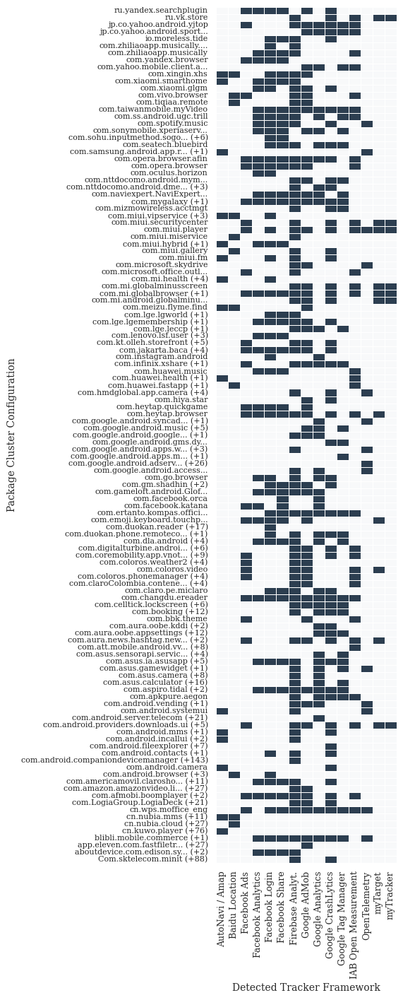

In [27]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. SCIENTIFIC TYPESETTING SETUP
sns.set_theme(style="white", context="paper")
plt.rcParams.update({
    'font.family': 'serif',
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 8
})

# 2. GENERATE CONDENSED MATRIX & PROCESS FINGERPRINTS
fingerprints = matrix_expanded.astype(str).agg(''.join, axis=1)
df_grouped = matrix_expanded.groupby(fingerprints)

df_condensed = df_grouped.first()
counts = df_grouped.size()

# Extract metadata into a temporary DataFrame for clean sorting
df_meta = pd.DataFrame({
    'rep_app': [g[0] for g in df_grouped.groups.values()],
    'count': counts.values
}, index=df_condensed.index)

# --- SORT ALPHABETICALLY BY RAW APP NAME ---
# ascending=False places 'A' at the top of the heatmap axis row order
df_meta = df_meta.sort_values(by='rep_app', ascending=False)
df_condensed = df_condensed.loc[df_meta.index]

# --- SYSTEM TARGET PACKAGES EXEMPTION RULE ---
def truncate_package_label(rep_app, cluster_count, max_len=25):
    clean_app = str(rep_app)
    # Bypass rule: never touch com.android.* strings
    if clean_app.startswith("com.android."):
        pass
    elif len(clean_app) > max_len:
        clean_app = f"{clean_app[:max_len]}..."
    return f"{clean_app} (+{cluster_count-1})" if cluster_count > 1 else clean_app

# Apply custom labels across your sorted indexes
df_condensed['Package Configuration'] = [
    truncate_package_label(row['rep_app'], row['count'], max_len=25)
    for _, row in df_meta.iterrows()
]
df_condensed['App Count'] = df_meta['count'].values

# 3. MELT & PRESERVE ORDER CATEGORICALLY
df_melted = df_condensed.melt(
    id_vars=['Package Configuration', 'App Count'],
    var_name='Tracker Name', value_name='Presence'
)

# Lock row sorting configuration explicitly
df_melted['Package Configuration'] = pd.Categorical(
    df_melted['Package Configuration'],
    categories=df_condensed['Package Configuration'].unique(),
    ordered=True
)

# Shorten outlier tracker framework names to avoid horizontal label overflow
tracker_rename_map = {
    "Huawei Mobile Services (HMS) Core": "HMS Core",
    "Google Firebase Analytics": "Firebase Analyt.",
    "OpenTelemetry (OpenCensus, OpenTracing)": "OpenTelemetry"
}
df_melted['Tracker Name'] = df_melted['Tracker Name'].replace(tracker_rename_map)

# 4. PIVOT MATRIX & PLOT HEATMAP
# We pivot using the categorical values to firmly preserve the vertical layout sequence
df_pivot = df_melted.pivot(
    index='Package Configuration',
    columns='Tracker Name',
    values='Presence'
).fillna(0)

# Ultra-compressed layout scaling (0.13 inches per configuration row)
num_configs = df_pivot.index.nunique()
fig_width = 3.3
fig_height = max(1.8, num_configs * 0.13)
fig, ax = plt.subplots(figsize=(fig_width, fig_height))

# Plot presence/absence alignment grid matrix
sns.heatmap(
    df_pivot > 0,
    cmap=['#f8f9fa', '#2c3e50'],   # High-contrast academic monochrome
    cbar=False,                     # No external bar blocks needed for binary charts
    linewidths=0.4,                 # Clean cell boundaries
    linecolor='#ffffff',
    xticklabels=True,
    yticklabels=True,
    ax=ax
)

plt.xlabel("Detected Tracker Framework", labelpad=4)
plt.ylabel("Package Cluster Configuration", labelpad=4)

plt.xticks(rotation=90, ha='center')
plt.yticks(rotation=0)

# Strip canvas margins to optimize single-column document footprint
for _, spine in ax.spines.items():
    spine.set_visible(False)
ax.tick_params(left=False, bottom=False)

plt.savefig("./images/trackers_clusters_heatmap.pdf", format='pdf', dpi=300, bbox_inches='tight')
plt.show()

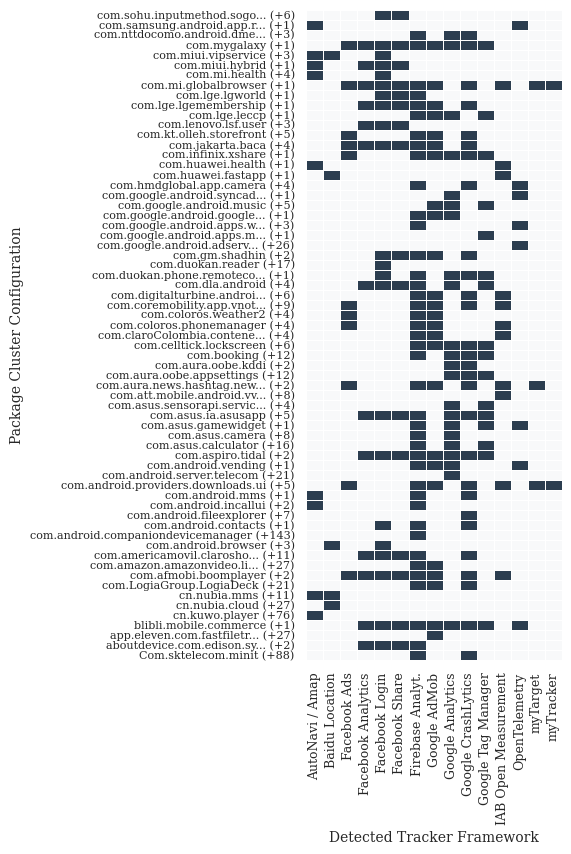

In [28]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. SCIENTIFIC TYPESETTING SETUP
sns.set_theme(style="white", context="paper")
plt.rcParams.update({
    'font.family': 'serif',
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 8
})

# 2. GENERATE CONDENSED MATRIX & PROCESS FINGERPRINTS
fingerprints = matrix_expanded.astype(str).agg(''.join, axis=1)
df_grouped = matrix_expanded.groupby(fingerprints)

df_condensed = df_grouped.first()
counts = df_grouped.size()

# Extract metadata into a temporary DataFrame for clean sorting
df_meta = pd.DataFrame({
    'rep_app': [g[0] for g in df_grouped.groups.values()],
    'count': counts.values
}, index=df_condensed.index)



# --- SORT ALPHABETICALLY BY RAW APP NAME ---
# ascending=False places 'A' at the top of the heatmap axis row order
df_meta = df_meta.sort_values(by='rep_app', ascending=False)
# Keep only configurations that represent at least 2 or 5 apps
df_meta = df_meta[df_meta['count'] >= 2]  # Adjust threshold as needed
df_condensed = df_condensed.loc[df_meta.index]

# --- SYSTEM TARGET PACKAGES EXEMPTION RULE ---
def truncate_package_label(rep_app, cluster_count, max_len=25):
    clean_app = str(rep_app)
    # Bypass rule: never touch com.android.* strings
    if clean_app.startswith("com.android."):
        pass
    elif len(clean_app) > max_len:
        clean_app = f"{clean_app[:max_len]}..."
    return f"{clean_app} (+{cluster_count-1})" if cluster_count > 1 else clean_app

# Apply custom labels across your sorted indexes
df_condensed['Package Configuration'] = [
    truncate_package_label(row['rep_app'], row['count'], max_len=25)
    for _, row in df_meta.iterrows()
]
df_condensed['App Count'] = df_meta['count'].values

# 3. MELT & PRESERVE ORDER CATEGORICALLY
df_melted = df_condensed.melt(
    id_vars=['Package Configuration', 'App Count'],
    var_name='Tracker Name', value_name='Presence'
)

# Lock row sorting configuration explicitly
df_melted['Package Configuration'] = pd.Categorical(
    df_melted['Package Configuration'],
    categories=df_condensed['Package Configuration'].unique(),
    ordered=True
)

# Shorten outlier tracker framework names to avoid horizontal label overflow
tracker_rename_map = {
    "Huawei Mobile Services (HMS) Core": "HMS Core",
    "Google Firebase Analytics": "Firebase Analyt.",
    "OpenTelemetry (OpenCensus, OpenTracing)": "OpenTelemetry"
}
df_melted['Tracker Name'] = df_melted['Tracker Name'].replace(tracker_rename_map)

# 4. PIVOT MATRIX & PLOT HEATMAP
# We pivot using the categorical values to firmly preserve the vertical layout sequence
df_pivot = df_melted.pivot(
    index='Package Configuration',
    columns='Tracker Name',
    values='Presence'
).fillna(0)

# Ultra-compressed layout scaling (0.13 inches per configuration row)
num_configs = df_pivot.index.nunique()
fig_width = 3.3
fig_height = max(1.8, num_configs * 0.13)
fig, ax = plt.subplots(figsize=(fig_width, fig_height))

# Plot presence/absence alignment grid matrix
sns.heatmap(
    df_pivot > 0,
    cmap=['#f8f9fa', '#2c3e50'],   # High-contrast academic monochrome
    cbar=False,                     # No external bar blocks needed for binary charts
    linewidths=0.4,                 # Clean cell boundaries
    linecolor='#ffffff',
    xticklabels=True,
    yticklabels=True,
    ax=ax
)

plt.xlabel("Detected Tracker Framework", labelpad=4)
plt.ylabel("Package Cluster Configuration", labelpad=4)

plt.xticks(rotation=90, ha='center')
plt.yticks(rotation=0)

# Strip canvas margins to optimize single-column document footprint
for _, spine in ax.spines.items():
    spine.set_visible(False)
ax.tick_params(left=False, bottom=False)

plt.savefig("./images/trackers_clusters_heatmap_condensed.pdf", format='pdf', dpi=300, bbox_inches='tight')
plt.show()

/var/folders/f_/b80d8wfj0bnckn_1q79yv01m0000gn/T/ipykernel_97537/3651661519.py:94: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(original_labels, rotation=45, ha='right')
/var/folders/f_/b80d8wfj0bnckn_1q79yv01m0000gn/T/ipykernel_97537/3651661519.py:97: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


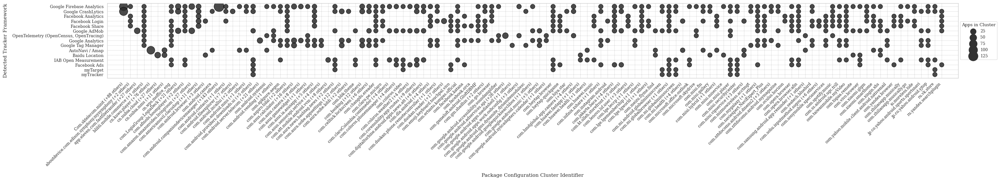

In [29]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ==============================================================================
# 1. SCIENTIFIC PAPER TYPESETTING CONFIGURATION
# ==============================================================================
sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update({
    'font.family': 'serif',
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 8.5,
    'ytick.labelsize': 9,
    'figure.titlesize': 14
})

# ==============================================================================
# 2. CONDENSE DATA & GENERATE UNIQUE FINGERPRINTS
# ==============================================================================
# Group matching binary fingerprints to completely flush out empty plot rows
fingerprints = matrix_expanded.astype(str).agg(lambda x: ''.join(x), axis=1)

new_rows = []
for idx, row in matrix_expanded.groupby(fingerprints):
    app_count = len(row)
    representative_app = row.index[0]

    # Label formatting identifying cluster grouping scale
    cluster_label = f"{representative_app} (+{app_count-1} others)" if app_count > 1 else representative_app

    row_dict = row.iloc[0].to_dict()
    row_dict['Package Configuration'] = cluster_label
    row_dict['App Count'] = app_count
    new_rows.append(row_dict)

df_condensed = pd.DataFrame(new_rows)

# Melt the dataset down for categorical scatterplotting
df_melted_paper = df_condensed.melt(
    id_vars=['Package Configuration', 'App Count'],
    var_name='Tracker Name',
    value_name='Presence'
)
df_melted_paper = df_melted_paper[df_melted_paper['Presence'] == 1]
df_melted_paper = df_melted_paper.sort_values(by='Package Configuration')

# ==============================================================================
# 3. OPTIMIZE FIGURE ENVIRONMENT ASPECT RATIO
# ==============================================================================
num_configs = df_melted_paper['Package Configuration'].nunique()

# Tighten horizontal spacing (slightly relaxed for 45-degree labels)
fig_width = max(10.0, num_configs * 0.28)
fig_height = 3.0

# Create the figure explicitly
fig, ax = plt.subplots(figsize=(fig_width, fig_height))

# ==============================================================================
# 4. DRAW THE SCATTERPLOT & APPLY CORRECT ALIGNMENT
# ==============================================================================
sns.scatterplot(
    data=df_melted_paper,
    x='Package Configuration',
    y='Tracker Name',
    size='App Count',
    sizes=(100, 500),
    color='#2b2b2b',
    alpha=0.85,
    edgecolor='black',
    legend='brief',
    ax=ax
)

# Set academic axis labels and descriptions
#plt.title("Ecosystem Profile: Unique Tracker Configurations in System Components", weight='bold', pad=18)
plt.ylabel("Detected Tracker Framework", labelpad=10)
plt.xlabel("Package Configuration Cluster Identifier", labelpad=14)
plt.legend(title="Apps in Cluster", loc='center left', bbox_to_anchor=(1, 0.5), frameon=True)
plt.grid(True, axis='both', linestyle=':', alpha=0.6, color='gray')

# --- REMOVE EMPTY WHITESPACE ---
# This forces the dots to stretch fully from edge to edge, removing empty margins
ax.margins(x=0.02)

# --- ALIGN FULL LABELS AT 45 DEGREES ---
plt.draw() # Forces matplotlib to calculate base positions first

# Extract the full, original text from the rendered labels
original_labels = [tick.get_text() for tick in ax.get_xticklabels()]

# Rotate 45 degrees and anchor to the right so they drop cleanly down and to the left
ax.set_xticklabels(original_labels, rotation=45, ha='right')

# Let Matplotlib automatically calculate the exact padding needed for the long diagonal text
plt.tight_layout()

plt.savefig("./images/tracker_clusters.pdf", format='pdf', dpi=300)
plt.show()

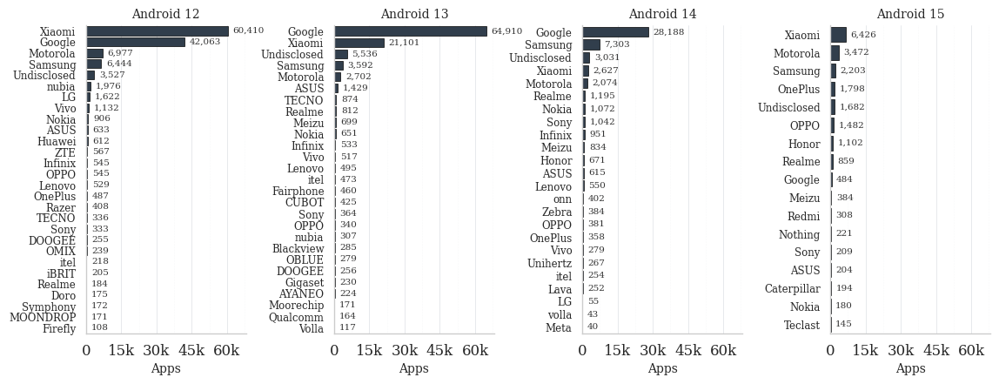

In [30]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ==========================================
# 1. SCIENTIFIC PAPER TYPESETTING
# ==========================================
sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update({
    'font.family': 'serif',
    'axes.labelsize': 10,
    'xtick.labelsize': 12,
    'ytick.labelsize': 8.5,
    'figure.titlesize': 11
})

# ==========================================
# 2. DATA PREPARATION & DENSITY FILTERING
# ==========================================
df_unique_apps = df_exodus_enriched.drop_duplicates(subset=['android_app_id_reference']).copy()
df_unique_apps = df_unique_apps.dropna(subset=['os_vendor', 'version_detected'])
df_unique_apps['version_detected'] = df_unique_apps['version_detected'].astype(int)

# FIX: Map 'Unknown' entries to 'Undisclosed' BEFORE grouping/counting
df_unique_apps['os_vendor'] = df_unique_apps['os_vendor'].astype(str).replace({
    'Unknown': 'Undisclosed',
    'unknown': 'Undisclosed',
    'None': 'Undisclosed',
    "Zebra Technologies": "Zebra"
})

# Count total apps per vendor-version intersection (now includes 'Undisclosed')
df_counts = df_unique_apps.groupby(['version_detected', 'os_vendor']).size().reset_index(name='App Count')

# OPTIONAL PAPER CLEANUP: 50 vendors across 5 panels is still a long vertical sprawl.
# If desired, uncomment these lines to isolate just top contributors or keep all 50.
# top_vendors = df_counts.groupby('os_vendor')['App Count'].sum().nlargest(25).index
# df_counts = df_counts[df_counts['os_vendor'].isin(top_vendors)]

# Sort systematically: high counts at the top of the horizontal plots
df_counts = df_counts.sort_values(by=['version_detected', 'App Count'], ascending=[True, False])



# ==========================================
# 3. RENDER SUBFIGURE GRID (FACETGRID)
# ==========================================
# col='version_detected' creates a clean 1-row grid with 5 parallel panels.
# height/aspect ratio is kept defensive to slide perfectly into a LaTeX document.
g = sns.FacetGrid(
    df_counts,
    col="version_detected",
    col_wrap=5,           # Aligns all 5 versions in a single row side-by-side
    sharex=True,          # Ensures easy comparison across the baseline scales
    sharey=False,         # CRITICAL: Allows each version to only list its active vendors
    height=4.5,
    aspect=0.65
)

# Map crisp horizontal bars to each subfigure
g.map_dataframe(
    sns.barplot,
    x="App Count",
    y="os_vendor",
    color="#2c3e50",      # Classic academic dark slate
    edgecolor="black",
    linewidth=0.5
)

# ==========================================
# 4. POLISH PANEL LABELS & INTERNALS
# ==========================================
import matplotlib.ticker as ticker

g.set_titles(template="Android {col_name}")
g.set_axis_labels("Apps", "")

# Define the formatting function for the X-ticks
def k_formatter(x, pos):
    if abs(x) >= 1000:
        # Formats to 15k, or 15.5k if there's a decimal fraction
        return f'{x*1e-3:.0f}k' if (x % 1000 == 0) else f'{x*1e-3:.1f}k'
    return f'{int(x)}'

for ax in g.axes.flat:
    # 1. Dynamically calculate smart major/minor spacing intervals
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=5, integer=True))
    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(n=2))

    # 2. Apply the dynamic 'k' abbreviation formatter to the major ticks
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(k_formatter))

    # 3. Draw the high-density grid hierarchy
    ax.grid(True, which='major', axis='x', linestyle='-', color='#d1d5db', alpha=0.6, linewidth=0.6)
    ax.grid(True, which='minor', axis='x', linestyle=':', color='#e5e7eb', alpha=0.5, linewidth=0.4)
    ax.set_axisbelow(True)

    # Maintain your discrete bar value readouts next to each bar
    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.annotate(
                f'{int(width):,}',
                (width, p.get_y() + p.get_height() / 2),
                ha='left',
                va='center',
                xytext=(4, 0),
                textcoords='offset points',
                fontsize=7.5,
                color='#333333'
            )

# Squeeze space slightly to accommodate the layout frame gracefully
plt.subplots_adjust(wspace=0.55)

# Save tight bounding vector asset for LaTeX integration
plt.savefig("./images/vendor_distribution_facets.pdf", format='pdf', dpi=300, bbox_inches='tight')
plt.show()

In [31]:
df_unique_apps.head()

,_id,_cls,report_date,android_app_id_reference,scanner_version,scanner_name,scan_status,error,trackers,application.handle,application.version_name,application.version_code,application.uaid,application.name,application.permissions,application.libraries,apk.path,apk.checksum,os_vendor,version_detected,firmware_id,filename,partition_name,tracker_names
960,6a4f4eb122324e493b7a8e3d,ApkScannerReport.ExodusReport,2026-07-09T07:33:02.498000,68b105d665e2ad36cf065848,1.3.12,Exodus,completed,NaN,[],com.android.bookmarkprovider,12,31,C63A317BC07C903459127DCF8E7BA84729EE87E3,Bookmark Provider,[],[],/var/www/file_store/01_file_storage/dc63ac8b-3292-4acd-8d78-781f7eb9ea5e/android_app_store/7d403426dcb5c5bfa7b38463f3a32a00/system/system.img_extract/raw.image_extract/0-875646976.extfs_extract/system/app/BookmarkProvider/BookmarkProvider.apk,b5d8898df49761cf62820f07d8f784b7ad26a147ad1e8a9593e2c7bc50ffcfe6,Google,12,68b1075d65e2ad36cf0776d5,BookmarkProvider.apk,system,[]
961,6a4f4eb1fa7e8ee5127a8e3d,ApkScannerReport.ExodusReport,2026-07-09T07:33:01.800000,68b105d665e2ad36cf065844,1.3.12,Exodus,completed,NaN,[],com.android.bluetoothmidiservice,12,31,302976DB5CA9E18AA9991B873D406CA4427C1F0B,Bluetooth MIDI Service,"[android.permission.BLUETOOTH_SCAN, android.permission.BLUETOOTH_CONNECT, android.permission.BLUETOOTH_ADVERTISE, android.permission.BLUETOOTH_ADMIN, android.permission.BLUETOOTH]",[],/var/www/file_store/01_file_storage/dc63ac8b-3292-4acd-8d78-781f7eb9ea5e/android_app_store/7d403426dcb5c5bfa7b38463f3a32a00/system/system.img_extract/raw.image_extract/0-875646976.extfs_extract/system/app/BluetoothMidiService/BluetoothMidiService.apk,911cdf6c13fd0b3d3c432c661ee1dab4edbd8cc1bed0cca029ef3ef6b95f5f8e,Google,12,68b1075d65e2ad36cf0776d5,BluetoothMidiService.apk,system,[]
962,6a4f4eb256df774d197a8e3d,ApkScannerReport.ExodusReport,2026-07-09T07:33:03.001000,68b105d665e2ad36cf06582e,1.3.12,Exodus,completed,NaN,[],com.android.dreams.basic,12,31,2A63D838026E670BA2952D48DE2A406CCF57F5BE,Basic Daydreams,[],[],/var/www/file_store/01_file_storage/dc63ac8b-3292-4acd-8d78-781f7eb9ea5e/android_app_store/7d403426dcb5c5bfa7b38463f3a32a00/system/system.img_extract/raw.image_extract/0-875646976.extfs_extract/system/app/BasicDreams/BasicDreams.apk,5a0900ec7b89f0ac562506e6ddc6b62c3ec52a532bec4064527dd999219769e5,Google,12,68b1075d65e2ad36cf0776d5,BasicDreams.apk,system,[]
963,6a4f4eb28147f5ecd97a8e3d,ApkScannerReport.ExodusReport,2026-07-09T07:33:02.704000,68b105d765e2ad36cf065944,1.3.12,Exodus,completed,NaN,[],com.android.providers.partnerbookmarks,12,31,B6718B2366709F5F60956644071E45BE959F37AA,,[],[],/var/www/file_store/01_file_storage/dc63ac8b-3292-4acd-8d78-781f7eb9ea5e/android_app_store/7d403426dcb5c5bfa7b38463f3a32a00/system/system.img_extract/raw.image_extract/0-875646976.extfs_extract/system/app/PartnerBookmarksProvider/PartnerBookmarksProvider.apk,67d14c800a89b54e33ffa1979a23f7c47dd1a6db18b42f45397adbc86d2c3912,Google,12,68b1075d65e2ad36cf0776d5,PartnerBookmarksProvider.apk,system,[]
964,6a4f4eb31aea578a3f7a8e3d,ApkScannerReport.ExodusReport,2026-07-09T07:33:05.799000,68b105d765e2ad36cf065892,1.3.12,Exodus,completed,NaN,[],com.android.htmlviewer,12,31,D0006C3E3E8A8064B66157DC68131364ABDBA355,HTML Viewer,[],[],/var/www/file_store/01_file_storage/dc63ac8b-3292-4acd-8d78-781f7eb9ea5e/android_app_store/7d403426dcb5c5bfa7b38463f3a32a00/system/system.img_extract/raw.image_extract/0-875646976.extfs_extract/system/app/HTMLViewer/HTMLViewer.apk,3c2dddb9262839eab44ac89b6f20678734a7126aa6fb1b63745c11241dfb878a,Google,12,68b1075d65e2ad36cf0776d5,HTMLViewer.apk,system,[]


In [32]:
# ==========================================
# FIX: ISOLATE UNIQUE PACKAGES FROM RAW DATA
# ==========================================
# 1. Use the clean, raw source dataframe
df_raw_pkgs = df_exodus_enriched.dropna(subset=['os_vendor', 'version_detected']).copy()

# Ensure integer types for versions
df_raw_pkgs['version_detected'] = df_raw_pkgs['version_detected'].astype(int)

# 2. Drop duplicates properly: We want unique combinations of [Package, Vendor, OS Version]
# This ensures a package is counted once per vendor layout it appears in.
package_column_name = 'application.handle' # Ensure this matches your exact column name

df_unique_packages = df_raw_pkgs.drop_duplicates(
    subset=[package_column_name, 'os_vendor', 'version_detected']
).copy()

# 3. Aggregate counts cleanly without fingerprint interference
df_pkg_counts = df_unique_packages.groupby(['version_detected', 'os_vendor']).size().reset_index(name='Package Count')
df_pkg_counts = df_pkg_counts.sort_values(by=['version_detected', 'Package Count'], ascending=[True, False])



In [33]:
df_unique_packages.head()

,_id,_cls,report_date,android_app_id_reference,scanner_version,scanner_name,scan_status,error,trackers,application.handle,application.version_name,application.version_code,application.uaid,application.name,application.permissions,application.libraries,apk.path,apk.checksum,os_vendor,version_detected,firmware_id,filename,partition_name,tracker_names
960,6a4f4eb122324e493b7a8e3d,ApkScannerReport.ExodusReport,2026-07-09T07:33:02.498000,68b105d665e2ad36cf065848,1.3.12,Exodus,completed,NaN,[],com.android.bookmarkprovider,12,31,C63A317BC07C903459127DCF8E7BA84729EE87E3,Bookmark Provider,[],[],/var/www/file_store/01_file_storage/dc63ac8b-3292-4acd-8d78-781f7eb9ea5e/android_app_store/7d403426dcb5c5bfa7b38463f3a32a00/system/system.img_extract/raw.image_extract/0-875646976.extfs_extract/system/app/BookmarkProvider/BookmarkProvider.apk,b5d8898df49761cf62820f07d8f784b7ad26a147ad1e8a9593e2c7bc50ffcfe6,Google,12,68b1075d65e2ad36cf0776d5,BookmarkProvider.apk,system,[]
961,6a4f4eb1fa7e8ee5127a8e3d,ApkScannerReport.ExodusReport,2026-07-09T07:33:01.800000,68b105d665e2ad36cf065844,1.3.12,Exodus,completed,NaN,[],com.android.bluetoothmidiservice,12,31,302976DB5CA9E18AA9991B873D406CA4427C1F0B,Bluetooth MIDI Service,"[android.permission.BLUETOOTH_SCAN, android.permission.BLUETOOTH_CONNECT, android.permission.BLUETOOTH_ADVERTISE, android.permission.BLUETOOTH_ADMIN, android.permission.BLUETOOTH]",[],/var/www/file_store/01_file_storage/dc63ac8b-3292-4acd-8d78-781f7eb9ea5e/android_app_store/7d403426dcb5c5bfa7b38463f3a32a00/system/system.img_extract/raw.image_extract/0-875646976.extfs_extract/system/app/BluetoothMidiService/BluetoothMidiService.apk,911cdf6c13fd0b3d3c432c661ee1dab4edbd8cc1bed0cca029ef3ef6b95f5f8e,Google,12,68b1075d65e2ad36cf0776d5,BluetoothMidiService.apk,system,[]
962,6a4f4eb256df774d197a8e3d,ApkScannerReport.ExodusReport,2026-07-09T07:33:03.001000,68b105d665e2ad36cf06582e,1.3.12,Exodus,completed,NaN,[],com.android.dreams.basic,12,31,2A63D838026E670BA2952D48DE2A406CCF57F5BE,Basic Daydreams,[],[],/var/www/file_store/01_file_storage/dc63ac8b-3292-4acd-8d78-781f7eb9ea5e/android_app_store/7d403426dcb5c5bfa7b38463f3a32a00/system/system.img_extract/raw.image_extract/0-875646976.extfs_extract/system/app/BasicDreams/BasicDreams.apk,5a0900ec7b89f0ac562506e6ddc6b62c3ec52a532bec4064527dd999219769e5,Google,12,68b1075d65e2ad36cf0776d5,BasicDreams.apk,system,[]
963,6a4f4eb28147f5ecd97a8e3d,ApkScannerReport.ExodusReport,2026-07-09T07:33:02.704000,68b105d765e2ad36cf065944,1.3.12,Exodus,completed,NaN,[],com.android.providers.partnerbookmarks,12,31,B6718B2366709F5F60956644071E45BE959F37AA,,[],[],/var/www/file_store/01_file_storage/dc63ac8b-3292-4acd-8d78-781f7eb9ea5e/android_app_store/7d403426dcb5c5bfa7b38463f3a32a00/system/system.img_extract/raw.image_extract/0-875646976.extfs_extract/system/app/PartnerBookmarksProvider/PartnerBookmarksProvider.apk,67d14c800a89b54e33ffa1979a23f7c47dd1a6db18b42f45397adbc86d2c3912,Google,12,68b1075d65e2ad36cf0776d5,PartnerBookmarksProvider.apk,system,[]
964,6a4f4eb31aea578a3f7a8e3d,ApkScannerReport.ExodusReport,2026-07-09T07:33:05.799000,68b105d765e2ad36cf065892,1.3.12,Exodus,completed,NaN,[],com.android.htmlviewer,12,31,D0006C3E3E8A8064B66157DC68131364ABDBA355,HTML Viewer,[],[],/var/www/file_store/01_file_storage/dc63ac8b-3292-4acd-8d78-781f7eb9ea5e/android_app_store/7d403426dcb5c5bfa7b38463f3a32a00/system/system.img_extract/raw.image_extract/0-875646976.extfs_extract/system/app/HTMLViewer/HTMLViewer.apk,3c2dddb9262839eab44ac89b6f20678734a7126aa6fb1b63745c11241dfb878a,Google,12,68b1075d65e2ad36cf0776d5,HTMLViewer.apk,system,[]


In [34]:
print(df_exodus_enriched['version_detected'].unique())

[12 13 14 15]


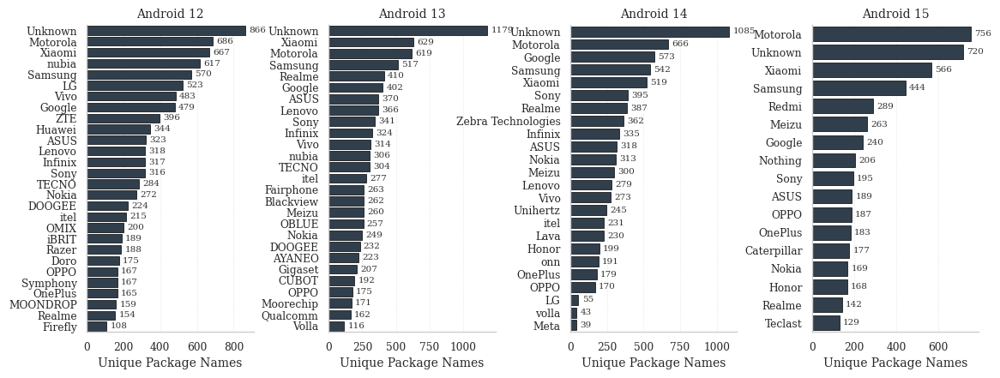

In [35]:
# ==========================================
# 4. PLOT THE SUBFIGURE FACETS
# ==========================================
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update({'font.family': 'serif', 'axes.labelsize': 10})

g = sns.FacetGrid(
    df_pkg_counts,
    col="version_detected",
    col_wrap=5,
    sharex=False,          # Set to False if count scales differ wildly between versions
    sharey=False,
    height=4.5,
    aspect=0.65
)

g.map_dataframe(
    sns.barplot,
    x="Package Count",
    y="os_vendor",
    color="#2c3e50",
    edgecolor="black",
    linewidth=0.5
)

g.set_titles(template="Android {col_name}")
g.set_axis_labels("Unique Package Names", "")

for ax in g.axes.flat:
    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.annotate(
                f'{int(width)}',
                (width, p.get_y() + p.get_height() / 2),
                ha='left', va='center', xytext=(3, 0),
                textcoords='offset points', fontsize=7.5, color='#333333'
            )
    ax.grid(True, axis='x', linestyle=':', alpha=0.5)
    ax.set_axisbelow(True)

plt.subplots_adjust(wspace=0.45)
plt.savefig("./images/package_distribution_facets.pdf", format='pdf', dpi=300, bbox_inches='tight')
plt.show()

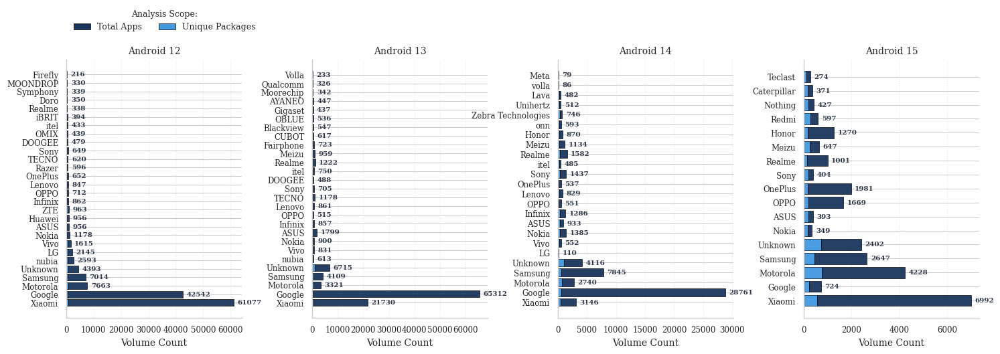

In [36]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ==========================================
# 1. SCIENTIFIC PAPER TYPESETTING
# ==========================================
sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update({
    'font.family': 'serif',
    'axes.labelsize': 10,
    'xtick.labelsize': 8.5,
    'ytick.labelsize': 8.5,
    'legend.fontsize': 9,
    'legend.title_fontsize': 9
})

# ==========================================
# 2. DUAL METRIC DATA AGGREGATION
# ==========================================
df_working = df_exodus.dropna(subset=['os_vendor', 'version_detected']).copy()
package_column_name = 'application.handle'

# Metric A: Total App Counts
df_apps = df_working.drop_duplicates(subset=['android_app_id_reference'])
apps_counts = df_apps.groupby(['version_detected', 'os_vendor']).size().reset_index(name='Count')
apps_counts['Metric'] = 'Total Apps'

# Metric B: Unique Package Names
df_pkgs = df_working.drop_duplicates(subset=[package_column_name, 'os_vendor', 'version_detected'])
pkgs_counts = df_pkgs.groupby(['version_detected', 'os_vendor']).size().reset_index(name='Unique Packages')
pkgs_counts = pkgs_counts.rename(columns={'Unique Packages': 'Count'})
pkgs_counts['Metric'] = 'Unique Packages'

df_combined = pd.concat([apps_counts, pkgs_counts], ignore_index=True)

df_sort_helper = apps_counts.sort_values(by=['version_detected', 'Count'], ascending=[True, False])
df_combined['os_vendor'] = pd.Categorical(
    df_combined['os_vendor'],
    categories=df_sort_helper['os_vendor'].unique(),
    ordered=True
)
df_combined = df_combined.sort_values(by=['version_detected', 'Metric'])

# ==========================================
# 3. CUSTOM STACKED MAPPING FUNCTION
# ==========================================
def draw_stacked_bars(data, **kwargs):
    """
    Pivots the long-form facet data to wide-form and plots horizontal stacked bars.
    """
    # Pivot current facet data to get columns for each metric
    df_pivot = data.pivot(index='os_vendor', columns='Metric', values='Count').fillna(0)

    # Ensure categorical sorting order is preserved along the Y-axis
    df_pivot = df_pivot.reindex(data['os_vendor'].cat.categories).dropna(how='all')

    y_positions = df_pivot.index

    # --- OPTION A: True Cumulative Stack (Unique Packages + Total Apps) ---
    # Base Layer: Unique Packages
    plt.barh(y_positions, df_pivot['Unique Packages'], color='#4299e1',
             edgecolor="black", linewidth=0.5, alpha=0.95, label='Unique Packages')

    # Stacked Layer: Total Apps (shifted right by the width of Unique Packages)
    plt.barh(y_positions, df_pivot['Total Apps'], left=df_pivot['Unique Packages'], color='#1a365d',
             edgecolor="black", linewidth=0.5, alpha=0.95, label='Total Apps')

    # --- OPTION B: Overlapping Subset Highlight ---
    # If "Unique Packages" is a subset of "Total Apps" and you want to show it *inside* the total:
    # plt.barh(y_positions, df_pivot['Total Apps'], color='#1a365d', edgecolor="black", linewidth=0.5, alpha=0.95)
    # plt.barh(y_positions, df_pivot['Unique Packages'], color='#4299e1', edgecolor="black", linewidth=0.5, alpha=0.95)

    # Inline Annotations
    for y_idx, vendor in enumerate(y_positions):
        val_unique = int(df_pivot.loc[vendor, 'Unique Packages'])
        val_total = int(df_pivot.loc[vendor, 'Total Apps'])

        # Total cumulative width where the bar ends
        total_width = val_unique + val_total  # Change to max(val_unique, val_total) if using Option B

        if total_width > 0:
            plt.annotate(
                f'{total_width}',
                (total_width, y_idx),
                ha='left', va='center',
                xytext=(4, 0), textcoords='offset points',
                fontsize=7.5, color='#2d3748', weight='bold'
            )

# ==========================================
# 4. RENDER PAIRED FACET GRID
# ==========================================
g = sns.FacetGrid(
    df_combined,
    col="version_detected",
    col_wrap=4,
    sharex=False,
    sharey=False,
    height=5.0,
    aspect=0.75
)

# Apply our custom stacked configuration
g.map_dataframe(draw_stacked_bars)

# Polish axes boundaries
g.set_titles(template="Android {col_name}")
g.set_axis_labels("Volume Count", "")

for ax in g.axes.flat:
    ax.grid(True, axis='x', linestyle=':', alpha=0.5)
    ax.set_axisbelow(True)

# Generate a clean, unified proxy legend manually since we bypassed standard hue tracking
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#1a365d', edgecolor='black', linewidth=0.5, label='Total Apps'),
    Patch(facecolor='#4299e1', edgecolor='black', linewidth=0.5, label='Unique Packages')
]

# Adjust positioning dynamically above the layout ceiling
g.axes.flat[0].legend(
    handles=legend_elements,
    title="Analysis Scope:",
    loc='lower left',
    bbox_to_anchor=(0.0, 1.08),
    ncol=2,
    frameon=False
)

plt.subplots_adjust(wspace=0.40, top=0.85)
plt.savefig("./images/unified_vendor_metrics_facets.pdf", format='pdf', dpi=300, bbox_inches='tight')
plt.show()

/Users/tom/Library/Python/3.9/lib/python/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
/Users/tom/Library/Python/3.9/lib/python/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
/Users/tom/Library/Python/3.9/lib/python/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future

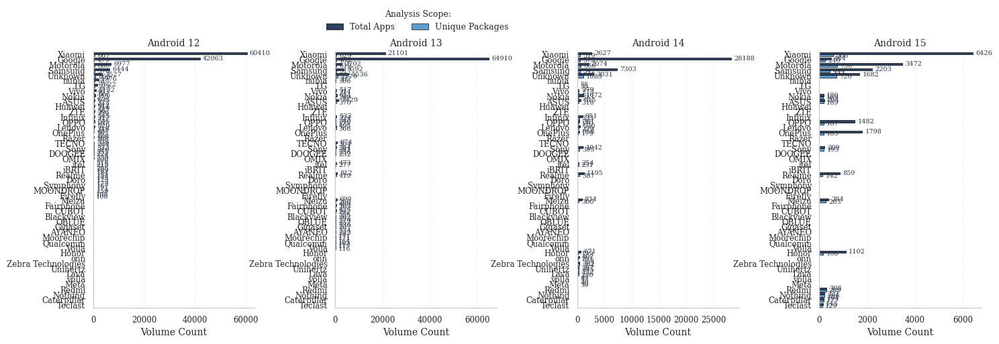

In [37]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ==========================================
# 1. SCIENTIFIC PAPER TYPESETTING
# ==========================================
sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update({
    'font.family': 'serif',
    'axes.labelsize': 10,
    'xtick.labelsize': 8.5,
    'ytick.labelsize': 8.5,
    'legend.fontsize': 9,
    'legend.title_fontsize': 9
})

# ==========================================
# 2. DUAL METRIC DATA AGGREGATION
# ==========================================
# Clean raw working frames (using your filtered df_exodus dataframe)
df_working = df_exodus.dropna(subset=['os_vendor', 'version_detected']).copy()
package_column_name = 'application.handle'  # Adjust to your exact column name if different

# Metric A: Total App Counts per Vendor/Version
df_apps = df_working.drop_duplicates(subset=['android_app_id_reference'])
apps_counts = df_apps.groupby(['version_detected', 'os_vendor']).size().reset_index(name='Count')
apps_counts['Metric'] = 'Total Apps'

# Metric B: Unique Package Names per Vendor/Version
df_pkgs = df_working.drop_duplicates(subset=[package_column_name, 'os_vendor', 'version_detected'])
pkgs_counts = df_pkgs.groupby(['version_detected', 'os_vendor']).size().reset_index(name='Unique Packages')
pkgs_counts = pkgs_counts.rename(columns={'Unique Packages': 'Count'})
pkgs_counts['Metric'] = 'Unique Packages'

# Combine both distributions into a long-form dataframe optimized for hue plotting
df_combined = pd.concat([apps_counts, pkgs_counts], ignore_index=True)

# Sort systematically so the heaviest layout configurations remain at the top
df_sort_helper = apps_counts.sort_values(by=['version_detected', 'Count'], ascending=[True, False])
df_combined['os_vendor'] = pd.Categorical(
    df_combined['os_vendor'],
    categories=df_sort_helper['os_vendor'].unique(),
    ordered=True
)
df_combined = df_combined.sort_values(by=['version_detected', 'Metric'])

# ==========================================
# 3. RENDER PAIRED FACET GRID
# ==========================================
# col_wrap=4 perfectly isolates your target SDK versions 12, 13, 14, and 15
g = sns.FacetGrid(
    df_combined,
    col="version_detected",
    col_wrap=4,
    sharex=False,          # Set to False so low-volume SDK axes optimize scale space
    sharey=False,
    height=5.0,
    aspect=0.75
)

# Render paired bars via hue mapping
g.map_dataframe(
    sns.barplot,
    x="Count",
    y="os_vendor",
    hue="Metric",
    palette=['#1a365d', '#4299e1'], # Deep Oxford Blue vs Clean Sky Blue
    edgecolor="black",
    linewidth=0.5,
    alpha=0.95
)

# ==========================================
# 4. POLISH INTERNALS & INLINE READOUTS
# ==========================================
g.set_titles(template="Android {col_name}")
g.set_axis_labels("Volume Count", "")

for ax in g.axes.flat:
    # Dynamically annotate the numbers next to their corresponding bars
    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.annotate(
                f'{int(width)}',
                (width, p.get_y() + p.get_height() / 2),
                ha='left',
                va='center',
                xytext=(3, 0),
                textcoords='offset points',
                fontsize=7.0,
                color='#2d3748'
            )
    ax.grid(True, axis='x', linestyle=':', alpha=0.5)
    ax.set_axisbelow(True)

# Build a singular, compact legend row above the plots to maximize single-column space
plt.legend(
    title="Analysis Scope:",
    loc='lower left',
    bbox_to_anchor=(-3.1, 1.05), # Spans horizontally across the ceiling frame columns
    ncol=2,
    frameon=False
)

plt.subplots_adjust(wspace=0.50, top=0.88)
plt.savefig("./images/unified_vendor_metrics_facets.pdf", format='pdf', dpi=300, bbox_inches='tight')
plt.show()

In [38]:
import pandas as pd

# ==========================================
# CREATE VENDOR SUMMARY TABLE WITH TOTALS
# ==========================================

# 1. Clean vendor labels to align with academic conventions
df_clean = df_exodus_enriched.copy()
df_clean['os_vendor'] = df_clean['os_vendor'].astype(str).replace({
    'Unknown': 'Undisclosed',
    'unknown': 'Undisclosed',
    'None': 'Undisclosed'
})

# 2. Total Apps per Vendor
df_total_apps = df_clean.groupby('os_vendor').size().rename('Total Apps')

# 3. Unique Packages per Vendor
df_unique_pkgs = df_clean.drop_duplicates(subset=['application.handle']).groupby('os_vendor').size().rename('Unique Pkgs')

# 4. Combine into a single summary DataFrame
# Shortened headers to save horizontal space in the LaTeX table
df_summary = pd.concat([df_total_apps, df_unique_pkgs], axis=1).reset_index()
df_summary.columns = ['Vendor', 'Total Apps', 'Unique Pkgs']

# 5. Sort table systematically by volume
df_summary = df_summary.sort_values(by='Total Apps', ascending=False).reset_index(drop=True)

# ------------------------------------------------------------------------------
# NEW: DYNAMICALLY COMPUTE UNIQUE VENDORS & OVERWRITE TOTAL LABEL
# ------------------------------------------------------------------------------
num_unique_vendors = df_summary['Vendor'].nunique()
# Shortened total label to prevent column stretching
total_row_label = f'\\textbf{{Total ({num_unique_vendors})}}'

# 6. Calculate totals and append them as the final row
total_row_idx = len(df_summary)
df_summary.loc[total_row_idx] = [
    total_row_label,
    df_summary['Total Apps'].sum(),
    df_summary['Unique Pkgs'].sum()
]

# Ensure integer formatting for numerical columns
df_summary['Total Apps'] = df_summary['Total Apps'].astype(int)
df_summary['Unique Pkgs'] = df_summary['Unique Pkgs'].astype(int)

# --- GENERATE LATEX TABLE STRING ---
print("\n--- LATEX CODE FOR PAPER ---")
# Generate raw LaTeX code
# escape=False is required so \textbf{} is not converted to raw text
latex_output = df_summary.to_latex(
    index=False,
    caption="Application distribution by vendor.",
    label="tab:vendor_dist",
    column_format="lrr",  # Left aligns vendor names, right aligns numbers
    escape=False
)

lines = latex_output.splitlines()

# Inject compact formatting commands immediately after \begin{table}
table_start_idx = next((i for i, line in enumerate(lines) if line.startswith('\\begin{table}')), -1)

if table_start_idx != -1:
    # \centering centers the table
    # \footnotesize reduces text size slightly to fit the column width
    # \setlength{\tabcolsep}{4pt} shrinks the horizontal padding between columns
    injections = [
        "\\centering",
        "\\footnotesize",
        "\\setlength{\\tabcolsep}{4pt}"
    ]
    for i, cmd in enumerate(injections):
        lines.insert(table_start_idx + 1 + i, cmd)

# Insert a professional dividing line (\midrule) right above the Total row
for idx, line in enumerate(lines):
    if '\\textbf{Total' in line:
        lines.insert(idx, '\\midrule')
        break

final_latex = "\n".join(lines)
print(final_latex)


--- LATEX CODE FOR PAPER ---
\begin{table}
\centering
\footnotesize
\setlength{\tabcolsep}{4pt}
\caption{Application distribution by vendor.}
\label{tab:vendor_dist}
\begin{tabular}{lrr}
\toprule
Vendor & Total Apps & Unique Pkgs \\
\midrule
Google & 135645 & 655 \\
Xiaomi & 90564 & 637 \\
Samsung & 19542 & 556 \\
Motorola & 15225 & 874 \\
Undisclosed & 13776 & 1113 \\
Realme & 3050 & 89 \\
ASUS & 2881 & 228 \\
Nokia & 2809 & 83 \\
OPPO & 2748 & 63 \\
OnePlus & 2643 & 36 \\
nubia & 2283 & 195 \\
Infinix & 2029 & 175 \\
Sony & 1948 & 221 \\
Vivo & 1928 & 283 \\
Meizu & 1917 & 138 \\
Honor & 1773 & 121 \\
LG & 1677 & 341 \\
Lenovo & 1574 & 197 \\
TECNO & 1210 & 24 \\
itel & 945 & 68 \\
Huawei & 612 & 268 \\
ZTE & 567 & 41 \\
DOOGEE & 511 & 48 \\
Fairphone & 460 & 25 \\
CUBOT & 425 & 8 \\
Razer & 408 & 24 \\
onn & 402 & 6 \\
Zebra Technologies & 384 & 165 \\
Redmi & 308 & 9 \\
Blackview & 285 & 46 \\
OBLUE & 279 & 40 \\
Unihertz & 267 & 4 \\
Lava & 252 & 24 \\
OMIX & 239 & 29 \\
Gigaset 

In [39]:
# ==============================================================================
# GENERATE UNIQUE FIRMWARE SUMMARY FROM MASTER DATAFRAME
# ==============================================================================
print("\nCalculating unique firmware distributions from master dataframe...")

# Identify the column containing your scanner module/class names
# (Matches the '_cls' field used during your file-splitting pipeline)
scanner_col_name = '_cls' if '_cls' in df_exodus_enriched.columns else 'class'

if scanner_col_name in df_exodus_enriched.columns:
    # 1. Total Records per Scanner Module
    df_total_rec = df_exodus_enriched.groupby(scanner_col_name).size().rename('Total Records')

    # 2. Mapped Records (rows where firmware_id is present and not NaN)
    # Filter the dataframe to only rows containing a valid firmware string before grouping
    df_mapped = df_exodus_enriched.dropna(subset=['firmware_id'])
    df_mapped_rec = df_mapped.groupby(scanner_col_name).size().rename('Mapped Records')

    # 3. Unique Hardware Firmware Images per Module
    df_unique_fw = df_exodus_enriched.groupby(scanner_col_name)['firmware_id'].nunique().rename('Unique Firmwares')

    # 4. Assemble the unified summary dataframe
    df_fw_summary = pd.concat([df_total_rec, df_mapped_rec, df_unique_fw], axis=1).reset_index()
    df_fw_summary.columns = ['Scanner Module', 'Total Records', 'Mapped Records', 'Unique Firmwares']

    # Fill any modules that failed to map completely with 0 instead of NaN
    df_fw_summary['Mapped Records'] = df_fw_summary['Mapped Records'].fillna(0).astype(int)

else:
    # Fallback structure if the master frame isn't split by class internally
    print(f"-> WARNING: '{scanner_col_name}' column not found in master dataframe. Creating global aggregation.")
    df_fw_summary = pd.DataFrame([{
        'Scanner Module': 'Global Dataset Summary',
        'Total Records': df_exodus_enriched.shape[0],
        'Mapped Records': df_exodus_enriched['firmware_id'].dropna().shape[0],
        'Unique Firmwares': df_exodus_enriched['firmware_id'].nunique()
    }])

# 5. Sort systematically by firmware volume footprint
df_fw_summary = df_fw_summary.sort_values(by='Unique Firmwares', ascending=False).reset_index(drop=True)

# 6. Append structural row for totals
total_row_idx = len(df_fw_summary)
df_fw_summary.loc[total_row_idx] = [
    '\\textbf{Total Covered}',
    df_fw_summary['Total Records'].sum(),
    df_fw_summary['Mapped Records'].sum(),
    df_fw_summary['Unique Firmwares'].sum()
]

# Print out readable summary matrix to standard output
print("\nFirmware Coverage Summary Table:")
print(df_fw_summary.to_string(index=False))

# --- GENERATE LATEX TABLE STRING ---
print("\n--- LATEX CODE FOR PAPER ---")
latex_output = df_fw_summary.to_latex(
    index=False,
    caption="Distribution of unique hardware firmware images and overall record health represented directly in the master dataset.",
    label="tab:master_firmware_coverage",
    column_format="lrrr"
)

# Inject standard academic line break before the total row
lines = latex_output.splitlines()
for idx, line in enumerate(lines):
    if '\\textbf{Total Covered}' in line:
        lines.insert(idx, '  \\midrule')
        break

print("\n".join(lines))


Calculating unique firmware distributions from master dataframe...

Firmware Coverage Summary Table:
               Scanner Module  Total Records  Mapped Records  Unique Firmwares
ApkScannerReport.ExodusReport         313946          313946              1056
       \textbf{Total Covered}         313946          313946              1056

--- LATEX CODE FOR PAPER ---
\begin{table}
\caption{Distribution of unique hardware firmware images and overall record health represented directly in the master dataset.}
\label{tab:master_firmware_coverage}
\begin{tabular}{lrrr}
\toprule
Scanner Module & Total Records & Mapped Records & Unique Firmwares \\
\midrule
ApkScannerReport.ExodusReport & 313946 & 313946 & 1056 \\
  \midrule
\textbf{Total Covered} & 313946 & 313946 & 1056 \\
\bottomrule
\end{tabular}
\end{table}


# Exporting the data to a file

In [40]:
%pip install "fastparquet"

Defaulting to user installation because normal site-packages is not writeable
  Using cached fastparquet-2024.11.0-cp39-cp39-macosx_11_0_arm64.whl.metadata (4.2 kB)
  Using cached cramjam-2.11.0-cp39-cp39-macosx_11_0_arm64.whl.metadata (5.6 kB)
Using cached fastparquet-2024.11.0-cp39-cp39-macosx_11_0_arm64.whl (684 kB)
Using cached cramjam-2.11.0-cp39-cp39-macosx_11_0_arm64.whl (1.7 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [fastparquet]

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: /Applications/Xcode.app/Contents/Developer/usr/bin/python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [41]:
df_exodus_enriched.to_parquet(f'{DATASET_PATH}static_analysis.parquet', engine='fastparquet')

# Permission baseline and tracker categories

This section adds two analyses to the tracker census:

1. **Permission baseline.** How often do apps *with* Exodus trackers request sensitive or privileged permissions, compared with apps *without* trackers, overall and by partition?
2. **Tracker categories.** Which Exodus categories (Advertisement, Analytics, Crash reporting, Identification, Location, Profiling) do the detected trackers belong to, by partition and by vendor?

The section is **self-contained**. It only needs `static_analysis.parquet` (in `DATASET_PATH`, produced above or copied from Zenodo) and the Exodus tracker registry `trackers.json` (both from Zenodo; `DataAnalysis/link_data.sh` links them into `DATASET_PATH`). You do not need to run the JSONL import cells above: run the first cell of this notebook (sets `DATASET_PATH`), then *Run Selected Cell and All Below* from here.

Tables are written as CSV and LaTeX to `DataAnalysis/tables/`. `exodus_trackers.zip` on Zenodo contains our copy of these tables for comparison.

**Counting unit.** As in the rest of RQ1, a unit is an app instance (one APK on one firmware image). Where noted, results are repeated with duplicate APKs (same SHA-256 checksum) counted once.

In [42]:
import os, json
import numpy as np
import pandas as pd
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
try:
    display
except NameError:          # allows running the cells outside Jupyter
    display = print

# ---- Inputs -----------------------------------------------------------------
STATIC_PARQUET = os.path.join(DATASET_PATH, "static_analysis.parquet")
TRACKER_REGISTRY = os.path.join(DATASET_PATH, "trackers.json")   # Exodus /api/trackers export (Zenodo; linked by link_data.sh)
TABLE_DIR = "tables"
os.makedirs(TABLE_DIR, exist_ok=True)

# Partitions in display order; partitions with very few tracker apps are flagged in the tables
PARTITIONS = ["system", "system_ext", "product", "vendor", "odm"]
MIN_GROUP = 100            # groups smaller than this are marked as too small to interpret
MIN_IMAGES = 10            # vendors with at least this many firmware images are shown

# Sensitive / privileged permissions reported in the paper
PERMISSIONS = [
    "WRITE_SECURE_SETTINGS", "INTERACT_ACROSS_USERS", "READ_PRIVILEGED_PHONE_STATE",
    "READ_PHONE_STATE", "QUERY_ALL_PACKAGES", "ACCESS_FINE_LOCATION",
    "CAMERA", "RECORD_AUDIO", "READ_CONTACTS",
]
CATEGORIES = ["Advertisement", "Analytics", "Crash reporting", "Identification", "Location", "Profiling"]

# AOSP-namespace packages; Play Store and Chrome are proprietary Google apps and excluded (as in the paper)
AOSP_PREFIX = "com.android."
AOSP_EXCLUDE = {"com.android.vending", "com.android.chrome"}

# ---- Load -------------------------------------------------------------------
cols = ["firmware_id", "os_vendor", "version_detected", "partition_name", "application.handle",
        "apk.checksum", "trackers", "application.permissions"]
sa = pd.read_parquet(STATIC_PARQUET, columns=cols)

def as_list(x):
    """Columns are stored as JSON strings in the parquet file, or as lists when the dataframe is in memory."""
    if x is None:
        return []
    if isinstance(x, str):
        return json.loads(x) if x else []
    if isinstance(x, float) and np.isnan(x):
        return []
    return list(x)

sa["trackers"] = sa["trackers"].map(as_list)
sa["permissions"] = sa["application.permissions"].map(as_list)
sa = sa.drop(columns=["application.permissions"])
sa["tracker_ids"] = sa["trackers"].map(lambda l: [int(t["id"]) for t in l if isinstance(t, dict) and "id" in t])
sa["has_tracker"] = sa["tracker_ids"].map(len) > 0
sa["n_permissions"] = sa["permissions"].map(len)

# One boolean column per permission (match on the short name, any namespace)
for p in PERMISSIONS:
    suffix = "." + p
    sa[p] = sa["permissions"].map(lambda l, s=suffix: any(str(e).endswith(s) for e in l))

sa["is_aosp_ns"] = sa["application.handle"].str.startswith(AOSP_PREFIX, na=False) & \
                   ~sa["application.handle"].isin(AOSP_EXCLUDE)

print(f"App instances:          {len(sa):,}")
print(f"Firmware images:        {sa.firmware_id.nunique():,}")
print(f"Instances with tracker: {sa.has_tracker.sum():,} ({100 * sa.has_tracker.mean():.1f}%)")

App instances:          313,946
Firmware images:        1,056
Instances with tracker: 28,780 (9.2%)


## Permission baseline: apps with vs. without trackers

The permission shares of tracker-carrying apps only mean something next to a baseline. Below, the same permissions are reported for apps without trackers.

**Empty permission lists.** A large share of apps declare no permission at all (mostly resource overlays / RROs, which are common in `product` and `vendor`). They are almost all tracker-free and therefore lower the baseline. The main table therefore **only counts apps that request at least one permission**; the unfiltered numbers are shown for comparison.

In [43]:
def perm_table(df, by):
    """Share (%) of apps requesting each permission, grouped by `by` (list of columns)."""
    g = df.groupby(by, observed=True)
    t = (100 * g[PERMISSIONS].mean()).round(1)
    t.insert(0, "n", g.size())
    return t

empty = sa["n_permissions"] == 0
print("Share of apps with an empty permission list:")
display((100 * sa.groupby("has_tracker")["n_permissions"].apply(lambda s: (s == 0).mean())).round(1)
        .rename(index={False: "no tracker", True: "tracker"}).to_frame("% empty"))
display((100 * empty.groupby(sa["partition_name"]).mean()).round(1).to_frame("% empty").T)

sa_perm = sa[~empty]

# 1a) All partitions combined
overall = pd.concat({
    "all apps": perm_table(sa, ["has_tracker"]),
    ">=1 permission": perm_table(sa_perm, ["has_tracker"]),
}, names=["population"])
overall = overall.rename(index={False: "no tracker", True: "tracker"}, level="has_tracker")
print("\n1a) Requested permissions (% of apps), all partitions")
display(overall)

Share of apps with an empty permission list:


,% empty
has_tracker,
no tracker,40.5
tracker,4.8


partition_name,odm,product,system,system_ext,vendor
% empty,78.5,50.5,24.8,12.7,80.6



1a) Requested permissions (% of apps), all partitions


n  WRITE_SECURE_SETTINGS  INTERACT_ACROSS_USERS  READ_PRIVILEGED_PHONE_STATE  READ_PHONE_STATE  QUERY_ALL_PACKAGES  ACCESS_FINE_LOCATION  CAMERA  RECORD_AUDIO  READ_CONTACTS
population     has_tracker                                                                                                                                                                                    
all apps       no tracker   285166                   13.4                   14.8                         17.3              13.3                18.0                  11.0     5.9           5.8            8.1
               tracker       28780                   35.5                   32.4                         29.1              45.2                42.7                  42.2    33.2          31.3           41.0
>=1 permission no tracker   169584                   22.6                   25.0                         29.2              22.4                30.3                  18.6    10.0           9.8           13.6
               tracker       27400                   37.2                   34.0                         30.6              47.5                44.8                  44.4    34.9          32.9           43.1

In [44]:
# 1b) Main table: by partition, apps with >= 1 permission
def by_partition(df):
    t = perm_table(df, ["partition_name", "has_tracker"])
    t = t.rename(index={False: "no tracker", True: "tracker"}, level="has_tracker")
    order = [p for p in PARTITIONS if p in t.index.get_level_values(0)]
    t = t.reindex(order, level=0)
    t["small_group"] = t["n"] < MIN_GROUP
    return t

perm_by_part = by_partition(sa_perm)
print(f"1b) Requested permissions (% of apps with >=1 permission), by partition "
      f"(small_group = fewer than {MIN_GROUP} apps)")
display(perm_by_part)

# Difference in percentage points (tracker - no tracker), for the text
diff = (perm_by_part.xs("tracker", level=1)[PERMISSIONS]
        - perm_by_part.xs("no tracker", level=1)[PERMISSIONS]).round(1).dropna(how="all")
print("Difference tracker - no tracker (percentage points):")
display(diff)

# 1c) Robustness: each distinct APK counted once
dedup = sa_perm.drop_duplicates("apk.checksum")
perm_by_part_dedup = by_partition(dedup)
print(f"1c) Same as 1b, distinct APKs only ({len(dedup):,} APKs)")
display(perm_by_part_dedup)

1b) Requested permissions (% of apps with >=1 permission), by partition (small_group = fewer than 100 apps)


n  WRITE_SECURE_SETTINGS  INTERACT_ACROSS_USERS  READ_PRIVILEGED_PHONE_STATE  READ_PHONE_STATE  QUERY_ALL_PACKAGES  ACCESS_FINE_LOCATION  CAMERA  RECORD_AUDIO  READ_CONTACTS  small_group
partition_name has_tracker                                                                                                                                                                                                
system         no tracker   85212                   19.5                   28.9                         21.9              16.4                33.0                  16.7     5.5           6.3           12.0        False
               tracker       6451                   46.3                   45.8                         36.7              40.6                53.1                  42.2    33.2          20.8           29.5        False
system_ext     no tracker   31926                   32.6                   25.2                         38.7              29.6                25.5                  11.1    10.2           4.6           11.1        False
               tracker       1297                   68.4                   13.5                         68.8              63.9                59.8                  53.8    53.8          45.4           44.5        False
product        no tracker   49793                   22.7                   18.4                         36.1              28.3                30.1                  27.2    18.1          19.5           18.8        False
               tracker      19621                   32.3                   31.5                         26.1              48.7                41.2                  44.5    34.2          36.0           47.5        False
vendor         no tracker    2630                    1.0                   18.1                         18.2              19.7                 5.0                   7.4     1.3           0.8            0.0        False
               tracker         31                    0.0                    0.0                          6.5              48.4                22.6                  61.3    58.1          54.8           29.0         True
odm            no tracker      23                    0.0                    0.0                          0.0               8.7                 0.0                   0.0     0.0           0.0            0.0         True

Difference tracker - no tracker (percentage points):


,WRITE_SECURE_SETTINGS,INTERACT_ACROSS_USERS,READ_PRIVILEGED_PHONE_STATE,READ_PHONE_STATE,QUERY_ALL_PACKAGES,ACCESS_FINE_LOCATION,CAMERA,RECORD_AUDIO,READ_CONTACTS
partition_name,,,,,,,,,
product,9.6,13.1,-10.0,20.4,11.1,17.3,16.1,16.5,28.7
system,26.8,16.9,14.8,24.2,20.1,25.5,27.7,14.5,17.5
system_ext,35.8,-11.7,30.1,34.3,34.3,42.7,43.6,40.8,33.4
vendor,-1.0,-18.1,-11.7,28.7,17.6,53.9,56.8,54.0,29.0


1c) Same as 1b, distinct APKs only (105,584 APKs)


n  WRITE_SECURE_SETTINGS  INTERACT_ACROSS_USERS  READ_PRIVILEGED_PHONE_STATE  READ_PHONE_STATE  QUERY_ALL_PACKAGES  ACCESS_FINE_LOCATION  CAMERA  RECORD_AUDIO  READ_CONTACTS  small_group
partition_name has_tracker                                                                                                                                                                                                
system         no tracker   50178                   20.2                   29.3                         23.3              15.9                33.2                  16.4     6.4           6.7           13.4        False
               tracker       3212                   46.1                   43.6                         46.0              38.5                54.1                  41.4    29.2          18.5           31.4        False
system_ext     no tracker   19246                   34.2                   24.8                         41.0              28.0                25.8                  13.3    12.1           5.4           11.3        False
               tracker        570                   41.9                   22.8                         39.6              53.9                48.4                  37.5    37.5          21.8           22.6        False
product        no tracker   23227                   22.2                   17.6                         39.7              25.0                26.4                  23.8    18.4          17.0           18.5        False
               tracker       7893                   26.2                   28.0                         22.7              49.9                43.1                  51.8    35.4          42.8           48.9        False
vendor         no tracker    1213                    1.6                   18.1                         18.1              18.9                 5.7                   6.3     1.8           1.2            0.1        False
               tracker         26                    0.0                    0.0                          3.8              50.0                19.2                  65.4    61.5          61.5           34.6         True
odm            no tracker      19                    0.0                    0.0                          0.0              10.5                 0.0                   0.0     0.0           0.0            0.0         True

In [45]:
# 1d) AOSP-namespace packages (com.android.*): the case discussed in the paper
aosp = sa[sa["is_aosp_ns"]]
host_pkgs = set(aosp.loc[aosp.has_tracker, "application.handle"])

aosp_cmp = pd.concat({
    "com.android.* with tracker": perm_table(aosp[aosp.has_tracker], ["is_aosp_ns"]),
    "com.android.* without tracker": perm_table(aosp[~aosp.has_tracker], ["is_aosp_ns"]),
    # Control: the same packages on images where they do NOT carry a tracker
    "same host packages, without tracker": perm_table(
        aosp[~aosp.has_tracker & aosp["application.handle"].isin(host_pkgs)], ["is_aosp_ns"]),
}).droplevel(1)
print(f"1d) AOSP-namespace packages: {len(host_pkgs)} packages host trackers")
display(aosp_cmp)
print("Note: the control row compares the same package names, so the gap to it is not explained "
      "by package identity alone.")

1d) AOSP-namespace packages: 26 packages host trackers


,n,WRITE_SECURE_SETTINGS,INTERACT_ACROSS_USERS,READ_PRIVILEGED_PHONE_STATE,READ_PHONE_STATE,QUERY_ALL_PACKAGES,ACCESS_FINE_LOCATION,CAMERA,RECORD_AUDIO,READ_CONTACTS
com.android.* with tracker,941,94.4,73.9,71.8,44.7,39.7,41.7,46.9,32.9,29.4
com.android.* without tracker,106877,10.3,14.9,12.8,8.3,17.1,6.8,3.0,3.6,7.8
"same host packages, without tracker",8875,46.7,57.9,45.0,41.5,42.4,30.8,23.9,17.6,41.0


Note: the control row compares the same package names, so the gap to it is not explained by package identity alone.


In [46]:
# Export tables of part 1
def export(df, name, caption):
    df.to_csv(os.path.join(TABLE_DIR, f"{name}.csv"))
    try:   # to_latex needs jinja2 >= 3.1.2
        with open(os.path.join(TABLE_DIR, f"{name}.tex"), "w") as f:
            f.write(df.to_latex(float_format="%.1f", caption=caption, label=f"tab:{name}"))
        print("wrote", os.path.join(TABLE_DIR, name + ".{csv,tex}"))
    except ImportError as e:
        print("wrote", os.path.join(TABLE_DIR, name + ".csv"), "(LaTeX skipped:", e, ")")

export(overall, "perm_baseline_overall", "Requested permissions (\\% of apps), apps with vs. without trackers.")
export(perm_by_part.drop(columns="small_group"), "perm_baseline_by_partition",
       "Requested permissions (\\% of apps with at least one permission) by partition, apps with vs. without trackers.")
export(perm_by_part_dedup.drop(columns="small_group"), "perm_baseline_by_partition_dedup",
       "As above, distinct APKs only.")
export(aosp_cmp, "perm_baseline_aosp_namespace",
       "Requested permissions (\\% of apps) of AOSP-namespace packages with and without trackers.")

wrote tables/perm_baseline_overall.{csv,tex}
wrote tables/perm_baseline_by_partition.{csv,tex}
wrote tables/perm_baseline_by_partition_dedup.{csv,tex}
wrote tables/perm_baseline_aosp_namespace.{csv,tex}


## Trackers by Exodus category

The Exodus scan results only store the tracker `id` and `name`. Categories come from the Exodus tracker registry (`trackers.json` in `DATASET_PATH`, an export of `https://reports.exodus-privacy.eu.org/api/trackers`), joined on the tracker id.

- A tracker can belong to **several categories** (e.g. IAB Open Measurement: Identification + Advertisement). An app is counted in a category if it carries **at least one** tracker of that category, so rows do not sum to 100%.
- Some registry entries have **no category**. Apps whose trackers are all uncategorised are reported in the column `Uncategorised only`, and the uncategorised trackers are listed below.
- The registry is a later snapshot than the scans (Exodus 1.3.12, July 2026). The cell below checks that every tracker id in the data exists in the registry with the same name.

In [51]:
with open(TRACKER_REGISTRY) as f:
    reg_raw = json.load(f)
reg_raw = reg_raw.get("trackers", reg_raw)
registry = {int(v["id"]): v for v in (reg_raw.values() if isinstance(reg_raw, dict) else reg_raw)}
print(f"Registry entries: {len(registry)}")

# Consistency check between scan results and registry
names_in_data = {}
occurrences = {}
for l in sa.loc[sa.has_tracker, "trackers"]:
    for t in l:
        i = int(t["id"]); names_in_data[i] = t["name"]; occurrences[i] = occurrences.get(i, 0) + 1
missing = sorted(i for i in names_in_data if i not in registry)
renamed = [(i, names_in_data[i], registry[i]["name"]) for i in names_in_data
           if i in registry and registry[i]["name"] != names_in_data[i]]
print(f"Distinct tracker ids in data: {len(names_in_data)}; missing from registry: {len(missing)}; "
      f"renamed: {len(renamed)}")
if missing: print("  missing ids:", missing)
if renamed: print("  renamed:", renamed)

def categories_of(tid):
    return list(registry.get(tid, {}).get("categories") or [])

uncat = pd.DataFrame([(names_in_data[i], occurrences[i]) for i in names_in_data if not categories_of(i)],
                     columns=["tracker", "app instances"]).sort_values("app instances", ascending=False)
total_occ = sum(occurrences.values())
print(f"Tracker detections without a registry category: {uncat['app instances'].sum():,} of {total_occ:,} "
      f"({100 * uncat['app instances'].sum() / total_occ:.1f}%)")
display(uncat.head(20))

# Category flags per app instance
sa["categories"] = sa["tracker_ids"].map(lambda ids: {c for i in ids for c in categories_of(i)})
for c in CATEGORIES:
    sa["cat_" + c] = sa["categories"].map(lambda s, c=c: c in s)
sa["cat_Uncategorised only"] = sa.has_tracker & (sa["categories"].map(len) == 0)
CAT_COLS = ["cat_" + c for c in CATEGORIES] + ["cat_Uncategorised only"]
CAT_LABELS = {k: k[4:] for k in CAT_COLS}

# Category of the most frequent trackers, for reference
top = pd.DataFrame([(names_in_data[i], occurrences[i], ", ".join(categories_of(i)) or "-")
                    for i in sorted(occurrences, key=occurrences.get, reverse=True)[:25]],
                   columns=["tracker", "app instances", "Exodus categories"])
display(top)

Registry entries: 432
Distinct tracker ids in data: 149; missing from registry: 0; renamed: 0
Tracker detections without a registry category: 5,922 of 63,126 (9.4%)


,tracker,app instances
0,Baidu Location,1042
1,Facebook Share,1014
2,myTracker,966
5,Bugly,700
3,AppMetrica,677
4,Baidu Map,407
8,Baidu Mobile Ads,162
9,Amazon Advertisement,152
6,Umeng Analytics,120
13,Adobe Experience Cloud,108


,tracker,app instances,Exodus categories
0,Google Firebase Analytics,18595,Analytics
1,Google AdMob,7534,Advertisement
2,Google CrashLytics,7000,Crash reporting
3,Google Analytics,5084,Analytics
4,Facebook Login,2774,Identification
5,Google Tag Manager,2175,Analytics
6,Facebook Ads,1721,Advertisement
7,AutoNavi / Amap,1409,Location
8,myTarget,1371,Advertisement
9,IAB Open Measurement,1226,"Identification, Advertisement"


In [52]:
# 2a) Category x partition
g = sa.groupby("partition_name")
cat_part_n = g[CAT_COLS].sum().rename(columns=CAT_LABELS)
cat_part_n.insert(0, "tracker apps", g["has_tracker"].sum())
cat_part_n.insert(0, "apps", g.size())
cat_part_n = cat_part_n.reindex([p for p in PARTITIONS if p in cat_part_n.index])

labels = list(CAT_LABELS.values())
cat_part_pct_tracker = (100 * cat_part_n[labels].div(cat_part_n["tracker apps"].replace(0, np.nan), axis=0)).round(1)
cat_part_pct_tracker.insert(0, "tracker apps", cat_part_n["tracker apps"])
cat_part_pct_all = (100 * cat_part_n[labels].div(cat_part_n["apps"], axis=0)).round(2)
cat_part_pct_all.insert(0, "apps", cat_part_n["apps"])

print("2a) Apps with >=1 tracker of the category (counts)");                display(cat_part_n)
print(f"2a) ... as % of tracker apps in the partition (groups < {MIN_GROUP} tracker apps are too small)")
display(cat_part_pct_tracker)
print("2a) ... as % of all apps in the partition");                         display(cat_part_pct_all)

2a) Apps with >=1 tracker of the category (counts)


,apps,tracker apps,Advertisement,Analytics,Crash reporting,Identification,Location,Profiling,Uncategorised only
partition_name,,,,,,,,,
system,121866,6455,1938,4669,2017,1336,1115,146,361
system_ext,38074,1297,204,1120,483,75,40,14,74
product,140174,20997,6811,18597,4980,2440,628,257,245
vendor,13725,31,19,27,18,8,8,2,0
odm,107,0,0,0,0,0,0,0,0


2a) ... as % of tracker apps in the partition (groups < 100 tracker apps are too small)


,tracker apps,Advertisement,Analytics,Crash reporting,Identification,Location,Profiling,Uncategorised only
partition_name,,,,,,,,
system,6455,30.0,72.3,31.2,20.7,17.3,2.3,5.6
system_ext,1297,15.7,86.4,37.2,5.8,3.1,1.1,5.7
product,20997,32.4,88.6,23.7,11.6,3.0,1.2,1.2
vendor,31,61.3,87.1,58.1,25.8,25.8,6.5,0.0
odm,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


2a) ... as % of all apps in the partition


,apps,Advertisement,Analytics,Crash reporting,Identification,Location,Profiling,Uncategorised only
partition_name,,,,,,,,
system,121866,1.59,3.83,1.66,1.10,0.91,0.12,0.30
system_ext,38074,0.54,2.94,1.27,0.20,0.11,0.04,0.19
product,140174,4.86,13.27,3.55,1.74,0.45,0.18,0.17
vendor,13725,0.14,0.20,0.13,0.06,0.06,0.01,0.00
odm,107,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [53]:
# 2b) Category x vendor (vendors with >= MIN_IMAGES firmware images), % of all apps of the vendor
gv = sa.groupby("os_vendor")
images = gv["firmware_id"].nunique()
keep = images[images >= MIN_IMAGES].index
cat_vendor = (100 * gv[CAT_COLS].mean()).rename(columns=CAT_LABELS).loc[keep].round(1)
cat_vendor.insert(0, "% apps with tracker", (100 * gv["has_tracker"].mean()).loc[keep].round(1))
cat_vendor.insert(0, "images", images.loc[keep])
cat_vendor = cat_vendor.sort_values("images", ascending=False)
print(f"2b) % of all apps carrying >=1 tracker of the category, vendors with >= {MIN_IMAGES} images")
display(cat_vendor)

2b) % of all apps carrying >=1 tracker of the category, vendors with >= 10 images


,images,% apps with tracker,Advertisement,Analytics,Crash reporting,Identification,Location,Profiling,Uncategorised only
os_vendor,,,,,,,,,
Google,462,8.8,2.2,8.0,1.0,0.0,0.0,0.0,0.0
Xiaomi,263,11.4,4.0,9.1,5.1,3.6,1.2,0.3,0.5
Unknown,65,6.3,2.6,4.7,1.5,0.8,0.5,0.1,0.3
Samsung,48,7.3,2.6,5.8,1.6,0.4,0.7,0.0,0.0
Motorola,43,8.6,2.8,7.8,2.8,1.1,0.4,0.4,0.3
OPPO,18,1.3,0.0,0.3,0.2,0.0,0.1,0.0,0.7
OnePlus,18,1.1,0.0,0.3,0.1,0.0,0.0,0.0,0.7
Realme,17,4.3,1.5,3.6,1.6,1.0,0.3,0.4,0.5
Nokia,12,6.2,2.2,5.9,1.4,0.1,0.2,0.0,0.0


In [54]:
# 2c) Advertising or identification SDKs in core partitions and in AOSP-namespace packages
CORE = ["system", "system_ext", "product"]
ad_id = sa["cat_Advertisement"] | sa["cat_Identification"]

core_ad = sa[ad_id & sa["partition_name"].isin(CORE)]
print(f"2c) Advertising or identification tracker in {CORE}: {len(core_ad):,} app instances, "
      f"{core_ad['application.handle'].nunique()} packages, {core_ad.firmware_id.nunique()} images, "
      f"{core_ad.os_vendor.nunique()} vendors")
display(core_ad["application.handle"].value_counts().head(15).to_frame("app instances"))
display(core_ad["os_vendor"].value_counts().head(10).to_frame("app instances"))

aosp_tr = sa[sa["is_aosp_ns"] & sa.has_tracker]
aosp_cat = aosp_tr[CAT_COLS].sum().rename(CAT_LABELS).to_frame("app instances")
aosp_cat["% of AOSP-namespace tracker apps"] = (100 * aosp_cat["app instances"] / len(aosp_tr)).round(1)
print(f"\nAOSP-namespace packages with trackers: {len(aosp_tr):,} app instances")
display(aosp_cat)

aosp_ad = aosp_tr[aosp_tr["cat_Advertisement"] | aosp_tr["cat_Identification"]]
print(f"AOSP-namespace packages with an advertising or identification tracker: {len(aosp_ad):,} instances, "
      f"{aosp_ad['application.handle'].nunique()} packages")
display(pd.crosstab(aosp_ad["application.handle"], aosp_ad["os_vendor"], margins=True, margins_name="total")
        .sort_values("total", ascending=False))

2c) Advertising or identification tracker in ['system', 'system_ext', 'product']: 10,899 app instances, 515 packages, 983 images, 45 vendors


,app instances
application.handle,
com.android.vending,903
com.google.android.youtube,819
com.google.android.gms,772
com.google.android.apps.youtube.music,697
com.google.android.googlequicksearchbox,586
com.google.android.videos,583
com.google.android.gms.policy_ads_fdr_dynamite,458
com.xiaomi.account,249
com.xiaomi.payment,247


,app instances
os_vendor,
Xiaomi,5302
Google,3048
Motorola,526
Samsung,509
Unknown,402
Infinix,150
Huawei,139
TECNO,85
ASUS,78



AOSP-namespace packages with trackers: 941 app instances


,app instances,% of AOSP-namespace tracker apps
Advertisement,479,50.9
Analytics,694,73.8
Crash reporting,450,47.8
Identification,337,35.8
Location,75,8.0
Profiling,150,15.9
Uncategorised only,18,1.9


AOSP-namespace packages with an advertising or identification tracker: 495 instances, 14 packages


os_vendor,Huawei,Redmi,Unknown,Vivo,Xiaomi,total
application.handle,,,,,,
total,4,1,14,4,472,495
com.android.providers.downloads.ui,0,0,3,0,170,173
com.android.thememanager,0,0,2,0,168,170
com.android.browser,0,0,3,0,71,74
com.android.camera,0,1,1,3,55,60
com.android.contacts,0,0,0,0,8,8
com.android.networkstack,0,0,2,0,0,2
com.android.VideoPlayer,0,0,0,1,0,1
com.android.bluetooth,0,0,1,0,0,1


In [55]:
# Export tables of part 2
export(cat_part_n, "tracker_category_by_partition_counts",
       "Apps carrying at least one tracker of each Exodus category, by partition.")
export(cat_part_pct_tracker, "tracker_category_by_partition",
       "Share of tracker-carrying apps (\\%) with at least one tracker of each Exodus category, by partition.")
export(cat_vendor, "tracker_category_by_vendor",
       "Share of apps (\\%) with at least one tracker of each Exodus category, vendors with at least 10 images.")
export(aosp_cat, "tracker_category_aosp_namespace",
       "Exodus categories of trackers in AOSP-namespace packages.")
uncat.to_csv(os.path.join(TABLE_DIR, "trackers_uncategorised.csv"), index=False)

wrote tables/tracker_category_by_partition_counts.{csv,tex}
wrote tables/tracker_category_by_partition.{csv,tex}
wrote tables/tracker_category_by_vendor.{csv,tex}
wrote tables/tracker_category_aosp_namespace.{csv,tex}
